**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
Erick Gabriel Santiago Suenaga

## Práctica 4: Meta aprendizaje (Ensambles de clasificadores)

---

**Pregunta.** ¿Cuánto ganan los ensambles sobre los cinco clasificadores base de la Práctica 3 cuando estos ya están bien ajustados?

Se responde con el conjunto de deserción estudiantil y con **los mismos cinco pliegues estratificados** de la Práctica 3. Los cinco clasificadores base (árbol de decisión, Naive Bayes, kNN, SVM y regresión logística) se recuperan con el preprocesamiento y los hiperparámetros que resultaron mejores en esa práctica, **sin repetir su optimización**. Sobre ellos se estudian las tres familias de ensambles:

1. **Bagging** (varianza): un árbol sin límite de profundidad contra bagging de esos árboles, y su versión optimizada (Random Forest y Extra-Trees).
2. **Boosting** (sesgo): un tocón contra AdaBoost de tocones, y su versión optimizada (XGBoost y LightGBM).
3. **Combinación de los cinco base**: votación dura, votación suave y *stacking* con meta-modelo logístico.

Después, el mejor modelo de la deserción se aplica al conjunto Bank Marketing (Tarea 4) y, en la Parte 2, se busca el mejor modelo para ese segundo conjunto con todo lo visto en el curso: preprocesamiento, balanceo de clases, clasificadores, optimización, umbral y ensambles. El modelo final de Bank Marketing se guarda en un archivo `.joblib`.

## Los dos conjuntos de datos

| | Deserción estudiantil (Práctica 3) | Bank Marketing (Tarea 4) |
|---|---|---|
| **Fuente** | UCI 697, *Predict Students' Dropout and Academic Success* (Realinho *et al.*, 2022) | UCI 222, *Bank Marketing* (Moro *et al.*, 2014) |
| **Archivo** | `desercion-entrenamiento.csv` (3,539 estudiantes) | `bank-additional-full.csv` (41,188 clientes, separado por `;`) |
| **Unidad** | Un estudiante de licenciatura | Un cliente contactado por teléfono |
| **Atributos usados** | 30 conocidos al cierre del 1.er semestre: 9 nominales, 8 binarios y 13 numéricos | 19: 10 categóricos y 9 numéricos (se quita `duration`, que solo se conoce después de la llamada) |
| **Objetivo** | `Target`: *Dropout* (32.1 %), *Enrolled* (17.9 %), *Graduate* (49.9 %) | `y`: 1 = *yes* (11.3 %), 0 = *no* (88.7 %) |
| **Validación** | Los 5 pliegues de la Práctica 3: `StratifiedKFold(5, shuffle=True, random_state=42)` | `StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)` |
| **Métrica** | F1-macro (media ± desviación entre pliegues) y sensibilidad de *Enrolled* | F1-macro (media ± desviación entre pliegues) y sensibilidad de *yes* |
| **Licencia** | CC BY 4.0 | CC BY 4.0 |

---

## Preparación

Se instalan versiones fijas de las librerías que cambian resultados (scikit-learn, XGBoost y LightGBM), se imprimen todas las versiones y se fija la semilla. Las rutas son relativas: los dos CSV deben estar en la misma carpeta que este notebook.

**Tiempo de ejecución.** En la computadora donde se ejecutó, el notebook completo tardó unos 9 minutos; en Google Colab (2 núcleos) puede tardar bastante más. Lo más caro son las búsquedas aleatorias y los ensambles sobre los 41,188 clientes.

In [1]:
%pip install -q scikit-learn==1.7.0 xgboost==3.0.2 lightgbm==4.6.0 scipy==1.16.3 pandas==2.2.3

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"        # también silencia los avisos en los procesos paralelos

import time, random, platform, warnings, pickle
from functools import partial

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import xgboost
import lightgbm
from cycler import cycler
from scipy.stats import loguniform, randint, uniform

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import (StratifiedKFold, RandomizedSearchCV, cross_validate, cross_val_predict,
                                     TunedThresholdClassifierCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler,
                                   KBinsDiscretizer, FunctionTransformer)
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (BaggingClassifier, AdaBoostClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, recall_score, make_scorer, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.exceptions import ConvergenceWarning, UndefinedMetricWarning
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.preprocessing._discretization")
warnings.filterwarnings("ignore", message=".*valid feature names.*")

SEMILLA = 42                 # la misma de la Práctica 3
SEMILLA_BANCO = 2026         # la que pide el enunciado para Bank Marketing
random.seed(SEMILLA)
np.random.seed(SEMILLA)
T_INICIO = time.perf_counter()

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 160)

print("Python      ", platform.python_version())
for nombre, modulo in [("numpy", np), ("pandas", pd), ("scipy", scipy), ("scikit-learn", sklearn),
                       ("xgboost", xgboost), ("lightgbm", lightgbm), ("matplotlib", matplotlib),
                       ("seaborn", sns), ("joblib", joblib)]:
    print(f"{nombre:<12}", modulo.__version__)

Python       3.12.10
numpy        2.5.4
pandas       2.2.3
scipy        1.16.3
scikit-learn 1.7.0
xgboost      3.0.2
lightgbm     4.6.0
matplotlib   3.11.2
seaborn      0.13.2
joblib       1.6.0


In [3]:
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
NARANJA = "#E76A28"
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
    "axes.prop_cycle": cycler(color=[AZUL_OSCURO, NARANJA, AZUL, GRIS]),
})

### Funciones comunes

- `registrar` evalúa un modelo con `cross_validate` y guarda, por pliegue, el F1-macro y la sensibilidad de la clase de interés, además del tiempo medio de entrenamiento por pliegue. Como todos los modelos usan los mismos pliegues, las diferencias se pueden comparar **pliegue a pliegue** (diferencias pareadas).
- `buscar` hace una búsqueda aleatoria con `RandomizedSearchCV` sobre los mismos pliegues y devuelve la tabla de configuraciones; `graficar_meseta` dibuja el F1 de cada configuración y el mejor alcanzado hasta ese momento.
- `PesosPorClase` agrega `class_weight` a XGBoost, que solo admite pesos por instancia (`sample_weight`).
- `traducir` adapta los pesos por clase de tres clases (Enrolled ×k) a dos clases (yes ×k) cuando una receta de la deserción se aplica a Bank Marketing.

In [4]:
def f1m(y_real, y_pred):
    return f1_score(y_real, y_pred, average="macro")


def registrar(tabla, nombre, familia, receta, X_, y_, cv, scoring, config=""):
    """Evalúa receta() con cross_validate y guarda los resultados por pliegue en `tabla`."""
    r = cross_validate(receta(), X_, y_, cv=cv, scoring=scoring, n_jobs=-1)
    tabla[nombre] = {"familia": familia, "f1": r["test_f1_macro"], "sens": r["test_sens"],
                     "tiempo": r["fit_time"].mean(), "config": config, "receta": receta}
    print(f"{nombre:<52} F1-macro {r['test_f1_macro'].mean():.4f} ± {r['test_f1_macro'].std():.4f} | "
          f"sens. {r['test_sens'].mean():.3f} | {r['fit_time'].mean():.2f} s por pliegue")


def buscar(modelo, espacio, X_, y_, cv, scoring, n_iter, criterio="f1_macro"):
    """Búsqueda aleatoria con los pliegues dados; devuelve la tabla de resultados y el índice de la mejor."""
    rs = RandomizedSearchCV(modelo, espacio, n_iter=n_iter, scoring=scoring, refit=False, cv=cv,
                            random_state=SEMILLA, n_jobs=-1, error_score=np.nan)
    t0 = time.perf_counter()
    rs.fit(X_, y_)
    cvr = pd.DataFrame(rs.cv_results_)
    i = int(cvr[f"mean_test_{criterio}"].idxmax())
    print(f"{len(cvr)} configuraciones ({cvr['params'].astype(str).nunique()} distintas) en "
          f"{time.perf_counter() - t0:.0f} s | mejor {criterio}: {cvr.loc[i, f'mean_test_{criterio}']:.4f} "
          f"(configuración {i + 1})")
    return cvr, i


def registrar_busqueda(tabla, nombre, familia, cvr, i, receta):
    """Guarda en `tabla` la mejor configuración de una búsqueda, con sus resultados por pliegue."""
    k = sum(c.startswith("split") and c.endswith("_test_f1_macro") for c in cvr.columns)
    f1 = np.array([cvr.loc[i, f"split{j}_test_f1_macro"] for j in range(k)])
    sens = np.array([cvr.loc[i, f"split{j}_test_sens"] for j in range(k)])
    tabla[nombre] = {"familia": familia, "f1": f1, "sens": sens, "tiempo": cvr.loc[i, "mean_fit_time"],
                     "config": formatear(cvr.loc[i, "params"]), "receta": receta}


def formatear(params):
    partes = []
    for k, v in params.items():
        k = k.replace("clf__estimator__", "").replace("clf__", "").replace("prep__nom", "nominales")
        if isinstance(v, OrdinalEncoder):
            v = "ordinal"
        elif isinstance(v, OneHotEncoder):
            v = f"one-hot (min_freq={v.min_frequency})"
        elif isinstance(v, (float, np.floating)):
            v = f"{v:.4g}"
        partes.append(f"{k}={v}")
    return ", ".join(partes)


def graficar_meseta(cvr, titulo, criterio="f1_macro", etiqueta="F1-macro de validación"):
    v = cvr[f"mean_test_{criterio}"].reset_index(drop=True)
    x = np.arange(1, len(v) + 1)
    mejor = v.cummax()
    ultima = int(np.argmax(v.to_numpy())) + 1
    mitad = mejor.iloc[len(v) // 2 - 1]
    inferior = max(v.min(), mejor.iloc[-1] - 0.12)
    fig, ax = plt.subplots(figsize=(7.2, 3.8))
    ax.scatter(x, v, s=14, alpha=0.45, color=AZUL, label="cada configuración")
    ax.plot(x, mejor, color=NARANJA, linewidth=2.2, label="mejor alcanzado")
    ax.axvline(ultima, color=GRIS, linestyle="--", linewidth=1)
    ax.text(ultima + 0.6, mejor.iloc[-1] + 0.003, f"última mejora: configuración {ultima}", color=GRIS, fontsize=8.5)
    ax.set_ylim(inferior - 0.005, mejor.iloc[-1] + 0.02)
    ax.set_xlabel("número de configuraciones evaluadas")
    ax.set_ylabel(etiqueta)
    ax.set_title(titulo)
    ax.legend(loc="lower right")
    plt.show()
    print(f"Mejor: {mejor.iloc[-1]:.4f} | a la mitad ({len(v) // 2} configuraciones) ya se tenía {mitad:.4f} | "
          f"mejora en la segunda mitad: {mejor.iloc[-1] - mitad:+.4f}")


def tabla_resultados(tabla, col_sens):
    filas = []
    for n, d in tabla.items():
        filas.append({"modelo": n, "familia": d["familia"], "_f1": d["f1"].mean(),
                      "F1-macro (media ± desv.)": f"{d['f1'].mean():.4f} ± {d['f1'].std():.4f}",
                      col_sens: round(float(d["sens"].mean()), 3),
                      "tiempo de entrenamiento (s/pliegue)": round(float(d["tiempo"]), 2),
                      "configuración": d["config"]})
    return pd.DataFrame(filas).sort_values("_f1", ascending=False).drop(columns="_f1").set_index("modelo")


def graficar_confusion(y_real, y_pred, etiquetas, titulo):
    cm = confusion_matrix(y_real, y_pred, labels=list(range(len(etiquetas))))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.1))
    sns.heatmap(pd.DataFrame(cm, index=etiquetas, columns=etiquetas), annot=True, fmt=",d", cmap="Blues",
                cbar=False, linewidths=1, annot_kws={"fontsize": 12}, ax=axes[0])
    axes[0].set_title("Número de casos")
    sns.heatmap(pd.DataFrame(cm_norm, index=etiquetas, columns=etiquetas), annot=True, fmt=".1%", cmap="Blues",
                cbar=False, linewidths=1, annot_kws={"fontsize": 12}, vmin=0, vmax=1, ax=axes[1])
    axes[1].set_title("Porcentaje de cada clase real")
    for ax in axes:
        ax.set_xlabel("clase predicha")
        ax.set_ylabel("clase real")
        ax.grid(False)
    fig.suptitle(titulo, x=0.01, ha="left", color=AZUL_OSCURO, fontweight="bold")
    plt.tight_layout()
    plt.show()
    return cm


class PesosPorClase(ClassifierMixin, BaseEstimator):
    """Envuelve un clasificador que solo acepta sample_weight (XGBoost) para darle `class_weight`."""

    def __init__(self, estimator=None, class_weight=None):
        self.estimator = estimator
        self.class_weight = class_weight

    def fit(self, X, y):
        pesos = None if self.class_weight is None else compute_sample_weight(self.class_weight, y)
        self.estimator_ = clone(self.estimator).fit(X, y, sample_weight=pesos)
        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)


def traducir(obj):
    """Pesos {0: a, 1: k, 2: b} de tres clases → {0: a, 1: k} de dos clases (la minoritaria es la 1)."""
    if isinstance(obj, dict):
        if set(obj) == {0, 1, 2}:
            return {0: obj[0], 1: obj[1]}
        return {k: traducir(v) for k, v in obj.items()}
    return obj

---

# Parte 1. Deserción estudiantil

## 1.0 Datos, pliegues y los cinco clasificadores base

Se cargan los datos exactamente como en la Práctica 3: los 30 atributos que se conocen al cierre del primer semestre y las clases codificadas como 0 = *Dropout*, 1 = *Enrolled*, 2 = *Graduate*. Los pliegues se construyen con la misma semilla (42), así que coinciden con los de la Práctica 3; se comprueba con su tamaño y con su proporción de clases.

In [5]:
tr = pd.read_csv("desercion-entrenamiento.csv")

NOMINALES = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
             "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
BINARIOS = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
            "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
NUMERICOS = ["Application order", "Previous qualification (grade)", "Admission grade", "Age at enrollment",
             "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
             "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
             "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
             "Unemployment rate", "Inflation rate", "GDP"]
ATRIBUTOS = NOMINALES + BINARIOS + NUMERICOS
COLS_DES = {"nom": NOMINALES, "bin": BINARIOS, "num": NUMERICOS}

CLASES = sorted(tr["Target"].unique())                     # Dropout, Enrolled, Graduate
X = tr[ATRIBUTOS]
y = tr["Target"].map({c: i for i, c in enumerate(CLASES)}).to_numpy()

PLIEGUES = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X, y))
SCORING_DES = {"f1_macro": "f1_macro", "sens": make_scorer(recall_score, labels=[1], average="macro")}

print("Estudiantes:", X.shape[0], "| atributos:", X.shape[1])
print("Pliegues (entrenamiento, validación):", [(len(a), len(b)) for a, b in PLIEGUES])
print("Proporción Dropout / Enrolled / Graduate en cada pliegue de validación:")
for _, idx in PLIEGUES:
    print("  ", np.round(np.bincount(y[idx]) / len(idx), 3))

Estudiantes: 3539 | atributos: 30
Pliegues (entrenamiento, validación): [(2831, 708), (2831, 708), (2831, 708), (2831, 708), (2832, 707)]
Proporción Dropout / Enrolled / Graduate en cada pliegue de validación:
   [0.321 0.179 0.5  ]
   [0.321 0.179 0.5  ]
   [0.322 0.179 0.499]
   [0.322 0.179 0.499]
   [0.321 0.18  0.499]


### Los cinco clasificadores de la Práctica 3, sin volver a optimizar

Se copian el preprocesamiento (siempre dentro de un `Pipeline`) y la mejor configuración que encontró la búsqueda de 100 configuraciones de la Práctica 3:

| Clasificador | Preprocesamiento | Mejor configuración (Práctica 3) | F1-macro (Práctica 3) |
|---|---|---|---|
| Árbol de decisión | Nominales one-hot (categorías con < 30 estudiantes agrupadas); resto tal cual | `entropy`, profundidad 8, ≥ 32 por hoja, `ccp_alpha` ≈ 0.0016, pesos `balanced` | 0.6451 ± 0.0101 |
| Naive Bayes | Categórico: nominales ordinales (< 10 agrupadas), numéricos en 6 bins por cuantiles | `alpha` ≈ 0.035, a priori estimados | 0.6253 ± 0.0073 |
| kNN | One-hot (< 30 agrupadas, peso del bloque 0.5) + escalado estándar | k = 19, votos por distancia, Manhattan | 0.5820 ± 0.0225 |
| SVM | One-hot (< 10 agrupadas) + escalado estándar | RBF, `C` ≈ 172.8, `gamma` ≈ 7.8e-4, Enrolled ×2 | 0.6886 ± 0.0092 |
| Regresión logística | One-hot (< 10 agrupadas) + escalado estándar | *Elastic net*, `C` ≈ 1.077, `l1_ratio` ≈ 0.398, Enrolled ×2 | 0.6815 ± 0.0066 |

Cada constructor recibe los grupos de columnas (`cols`) para poder reutilizar la misma receta en Bank Marketing (sección 1.7). El argumento `banco` solo cambia el SVM: con 33 mil clientes de entrenamiento por pliegue, un SVC con kernel RBF y `C` ≈ 173 tarda demasiado, así que en ese conjunto el kernel se aproxima con Nyström (300 componentes, mismo `gamma`) y un SVM lineal con el mismo `C`.

In [6]:
def onehot(min_freq):
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_freq, sparse_output=False)


def ordinal():
    return OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)


SUMAR_UNO = partial(np.add, 1)        # CategoricalNB exige códigos >= 0 (las categorías nuevas quedan en 0)


def construir_arbol(p, cols, banco=False):
    nom = onehot(p["min_freq"]) if p["codificacion"] == "onehot" else ordinal()
    prep = ColumnTransformer([("nom", nom, cols["nom"])], remainder="passthrough")
    clf = DecisionTreeClassifier(criterion=p["criterion"], max_depth=p["max_depth"],
                                 min_samples_leaf=p["min_samples_leaf"], ccp_alpha=p["ccp_alpha"],
                                 class_weight=p["class_weight"], random_state=SEMILLA)
    return Pipeline([("prep", prep), ("arbol", clf)])


def construir_nb(p, cols, banco=False):
    nom = Pipeline([("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                           min_frequency=p["min_freq"])),
                    ("mas1", FunctionTransformer(SUMAR_UNO))])
    disc = KBinsDiscretizer(n_bins=p["n_bins"], encode="ordinal", strategy="quantile",
                            quantile_method="averaged_inverted_cdf")
    prep = ColumnTransformer([("nom", nom, cols["nom"]), ("num", disc, cols["num"])], remainder="passthrough")
    return Pipeline([("prep", prep), ("nb", CategoricalNB(alpha=p["alpha"], fit_prior=p["fit_prior"]))])


def construir_knn(p, cols, banco=False):
    esc = StandardScaler() if p["escalador"] == "estandar" else MinMaxScaler()
    prep = ColumnTransformer([("nom", onehot(p["min_freq"]), cols["nom"]), ("num", esc, cols["num"] + cols["bin"])],
                             transformer_weights={"nom": p["peso_nominal"], "num": 1.0})
    clf = KNeighborsClassifier(n_neighbors=p["n_neighbors"], weights=p["weights"], metric=p["metric"])
    return Pipeline([("prep", prep), ("knn", clf)])


def construir_svm(p, cols, banco=False):
    prep = ColumnTransformer([("nom", onehot(p["min_freq"]), cols["nom"]),
                              ("num", StandardScaler(), cols["num"] + cols["bin"])])
    if not banco:
        clf = SVC(kernel="rbf", C=p["C"], gamma=p["gamma"], class_weight=p["class_weight"],
                  cache_size=500, random_state=SEMILLA)
    else:   # aproximación del kernel RBF para los 41 mil clientes de Bank Marketing
        clf = Pipeline([("nystroem", Nystroem(kernel="rbf", gamma=p["gamma"], n_components=300, random_state=SEMILLA)),
                        ("lineal", LinearSVC(C=p["C"], class_weight=p["class_weight"], dual=False, max_iter=5000,
                                             random_state=SEMILLA))])
    return Pipeline([("prep", prep), ("svm", clf)])


def construir_lr(p, cols, banco=False):
    prep = ColumnTransformer([("nom", onehot(p["min_freq"]), cols["nom"]),
                              ("num", StandardScaler(), cols["num"] + cols["bin"])])
    clf = LogisticRegression(penalty="elasticnet", solver="saga", C=p["C"], l1_ratio=p["l1_ratio"],
                             class_weight=p["class_weight"], max_iter=1000, tol=1e-3, random_state=SEMILLA)
    return Pipeline([("prep", prep), ("logistica", clf)])


ENROLLED_X2 = {0: 1.0, 1: 2.0, 2: 1.0}
P3 = {   # mejores configuraciones de la Práctica 3 (no se vuelven a buscar)
    "Árbol de decisión": dict(codificacion="onehot", min_freq=30, criterion="entropy", max_depth=8,
                              min_samples_leaf=32, ccp_alpha=0.001606, class_weight="balanced"),
    "Naive Bayes": dict(min_freq=10, n_bins=6, alpha=0.035114, fit_prior=True),
    "kNN": dict(escalador="estandar", min_freq=30, peso_nominal=0.5, n_neighbors=19, weights="distance",
                metric="manhattan"),
    "SVM": dict(C=172.76056747028196, gamma=0.0007777904549497886, class_weight=ENROLLED_X2, min_freq=10),
    "Regresión logística": dict(C=1.076825, l1_ratio=0.397826, class_weight=ENROLLED_X2, min_freq=10),
}
F1_P3 = {"Árbol de decisión": 0.6451, "Naive Bayes": 0.6253, "kNN": 0.5820, "SVM": 0.6886,
         "Regresión logística": 0.6815}
CONSTRUCTORES = {"Árbol de decisión": construir_arbol, "Naive Bayes": construir_nb, "kNN": construir_knn,
                 "SVM": construir_svm, "Regresión logística": construir_lr}
ALIAS = {"Árbol de decisión": "arbol", "Naive Bayes": "nb", "kNN": "knn", "SVM": "svm",
         "Regresión logística": "logistica"}
BASES = list(P3)


def base(nombre, banco=False):
    """Clasificador base de la Práctica 3 (en Bank Marketing, con columnas y pesos adaptados)."""
    cols = COLS_BANCO if banco else COLS_DES
    p = traducir(P3[nombre]) if banco else P3[nombre]
    return CONSTRUCTORES[nombre](p, cols, banco)


RES = {}         # resultados de la deserción: nombre → F1 y sensibilidad por pliegue, tiempo, configuración, receta
RECETAS = {}     # nombre → función receta(banco=False) que construye el modelo sin entrenar

for n in BASES:
    RECETAS[n] = partial(base, n)
    registrar(RES, n, "Base", RECETAS[n], X, y, PLIEGUES, SCORING_DES, config=formatear(P3[n]))

Árbol de decisión                                    F1-macro 0.6451 ± 0.0101 | sens. 0.633 | 0.03 s por pliegue


Naive Bayes                                          F1-macro 0.6253 ± 0.0073 | sens. 0.417 | 0.02 s por pliegue


kNN                                                  F1-macro 0.5820 ± 0.0225 | sens. 0.164 | 0.01 s por pliegue


SVM                                                  F1-macro 0.6886 ± 0.0092 | sens. 0.559 | 0.32 s por pliegue


Regresión logística                                  F1-macro 0.6815 ± 0.0066 | sens. 0.531 | 0.98 s por pliegue


In [7]:
verif = pd.DataFrame({"F1-macro Práctica 3": F1_P3,
                      "F1-macro ahora": {n: RES[n]["f1"].mean() for n in BASES}})
verif["diferencia"] = verif["F1-macro ahora"] - verif["F1-macro Práctica 3"]
print(verif.round(4).to_string())

                     F1-macro Práctica 3  F1-macro ahora  diferencia
Árbol de decisión                 0.6451          0.6451         0.0
Naive Bayes                       0.6253          0.6253        -0.0
kNN                               0.5820          0.5820         0.0
SVM                               0.6886          0.6886        -0.0
Regresión logística               0.6815          0.6815         0.0


**Lectura.** Los cinco clasificadores reproducen el F1-macro de la Práctica 3 hasta la cuarta cifra decimal: SVM 0.6886, regresión logística 0.6815, árbol 0.6451, Naive Bayes 0.6253 y kNN 0.5820. Los pliegues y las configuraciones son, entonces, los mismos, y cualquier ganancia de los ensambles se mide contra los base **tal como quedaron** al final de la Práctica 3. El punto de referencia es el SVM (0.6886 ± 0.0092).

---

## 1.1 Varianza: un árbol sin límite de profundidad contra bagging de árboles

Un árbol sin límite de profundidad crece hasta que cada hoja es pura: casi no tiene sesgo (en entrenamiento acierta prácticamente todo), pero tiene **mucha varianza**, porque pequeños cambios en los datos cambian los cortes de arriba y, con ellos, todo el árbol. *Bagging* (Breiman, 1996) entrena muchos árboles así, cada uno con una muestra *bootstrap* del entrenamiento, y promedia sus probabilidades.

Para cada uno de los cinco pliegues se ajusta el preprocesamiento del árbol (nominales en one-hot con categorías raras agrupadas) solo con el entrenamiento y se agregan árboles con `warm_start=True` hasta 1, 5, 10, 20, 50, 100, 200, 300 y 400. Con los 400 árboles del último paso se mide además:

- el F1-macro de **cada árbol por separado** (su promedio y su dispersión, que son el sesgo y la varianza de un árbol suelto),
- el **desacuerdo**: la fracción de votos de los árboles individuales que difieren de la predicción del bagging,
- el F1-macro en **entrenamiento** del árbol y del bagging.

In [8]:
N_ARBOLES = [1, 5, 10, 20, 50, 100, 200, 300, 400]


def prep_arboles(cols):
    return ColumnTransformer([("nom", onehot(30), cols["nom"])], remainder="passthrough")


k_pl = len(PLIEGUES)
curva_bag = np.zeros((k_pl, len(N_ARBOLES)))
f1_arbol, f1_arbol_ent, f1_bag_ent = np.zeros(k_pl), np.zeros(k_pl), np.zeros(k_pl)
f1_indiv_media, f1_indiv_sd, desacuerdo = np.zeros(k_pl), np.zeros(k_pl), np.zeros(k_pl)

t0 = time.perf_counter()
for k, (i_tr, i_va) in enumerate(PLIEGUES):
    prep = prep_arboles(COLS_DES).fit(X.iloc[i_tr])
    X_tr, X_va = prep.transform(X.iloc[i_tr]), prep.transform(X.iloc[i_va])
    y_tr, y_va = y[i_tr], y[i_va]

    arbol = DecisionTreeClassifier(random_state=SEMILLA).fit(X_tr, y_tr)
    f1_arbol[k] = f1m(y_va, arbol.predict(X_va))
    f1_arbol_ent[k] = f1m(y_tr, arbol.predict(X_tr))

    bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=1, warm_start=True,
                            random_state=SEMILLA, n_jobs=-1)
    for j, n in enumerate(N_ARBOLES):
        bag.set_params(n_estimators=n).fit(X_tr, y_tr)        # warm_start: solo agrega los árboles que faltan
        curva_bag[k, j] = f1m(y_va, bag.predict(X_va))
    f1_bag_ent[k] = f1m(y_tr, bag.predict(X_tr))

    # cada árbol del bagging vio las columnas en el orden de estimators_features_
    votos = np.array([e.predict(X_va[:, f]) for e, f in zip(bag.estimators_, bag.estimators_features_)])
    f1_ind = [f1m(y_va, v) for v in votos]
    f1_indiv_media[k], f1_indiv_sd[k] = np.mean(f1_ind), np.std(f1_ind)
    desacuerdo[k] = (votos != bag.predict(X_va)).mean()
print(f"Curva de bagging: {time.perf_counter() - t0:.0f} s")

pd.DataFrame({"árboles": N_ARBOLES, "F1-macro (media)": curva_bag.mean(0), "F1-macro (desv.)": curva_bag.std(0)}
             ).set_index("árboles").round(4).T

Curva de bagging: 78 s


árboles,1,5,10,20,50,100,200,300,400
F1-macro (media),0.5680,0.6126,0.6345,0.6446,0.6572,0.6578,0.6599,0.6639,0.6611
F1-macro (desv.),0.0161,0.0139,0.0130,0.0153,0.0169,0.0253,0.0231,0.0293,0.0258


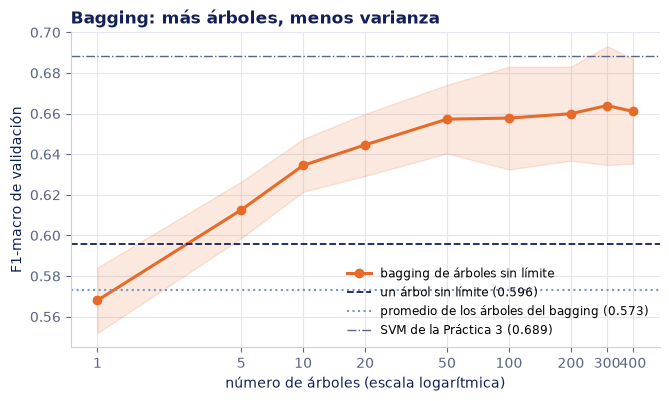

                        F1-macro entrenamiento  F1-macro validación (media)  F1-macro validación (desv. entre pliegues)
un árbol sin límite                        1.0                       0.5960                                      0.0052
bagging de 400 árboles                     1.0                       0.6611                                      0.0258

Árboles individuales del bagging: F1-macro 0.5730 en promedio, con desviación de 0.0175 entre árboles del mismo pliegue.
Desacuerdo: 26.4% de los votos individuales difieren de la predicción del bagging.
Ganancia de bagging sobre un árbol: +0.0651 de F1-macro; de 1 a 50 árboles: +0.0892; de 50 a 400: +0.0038.


In [9]:
m_bag, s_bag = curva_bag.mean(0), curva_bag.std(0)
fig, ax = plt.subplots(figsize=(7.6, 4.1))
ax.plot(N_ARBOLES, m_bag, marker="o", color=NARANJA, linewidth=2.2, label="bagging de árboles sin límite")
ax.fill_between(N_ARBOLES, m_bag - s_bag, m_bag + s_bag, color=NARANJA, alpha=0.15)
ax.axhline(f1_arbol.mean(), color=AZUL_OSCURO, linestyle="--", linewidth=1.3,
           label=f"un árbol sin límite ({f1_arbol.mean():.3f})")
ax.axhline(f1_indiv_media.mean(), color=AZUL, linestyle=":", linewidth=1.5,
           label=f"promedio de los árboles del bagging ({f1_indiv_media.mean():.3f})")
ax.axhline(RES["SVM"]["f1"].mean(), color=GRIS, linestyle="-.", linewidth=1,
           label=f"SVM de la Práctica 3 ({RES['SVM']['f1'].mean():.3f})")
ax.set_xscale("log")
ax.set_xticks(N_ARBOLES)
ax.set_xticklabels(N_ARBOLES)
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xlabel("número de árboles (escala logarítmica)")
ax.set_ylabel("F1-macro de validación")
ax.set_title("Bagging: más árboles, menos varianza")
ax.legend(loc="lower right", fontsize=8.5)
plt.show()

diag = pd.DataFrame({
    "F1-macro entrenamiento": [f1_arbol_ent.mean(), f1_bag_ent.mean()],
    "F1-macro validación (media)": [f1_arbol.mean(), m_bag[-1]],
    "F1-macro validación (desv. entre pliegues)": [f1_arbol.std(), s_bag[-1]],
}, index=["un árbol sin límite", "bagging de 400 árboles"])
print(diag.round(4).to_string())
print(f"\nÁrboles individuales del bagging: F1-macro {f1_indiv_media.mean():.4f} en promedio, "
      f"con desviación de {f1_indiv_sd.mean():.4f} entre árboles del mismo pliegue.")
print(f"Desacuerdo: {desacuerdo.mean():.1%} de los votos individuales difieren de la predicción del bagging.")
print(f"Ganancia de bagging sobre un árbol: {m_bag[-1] - f1_arbol.mean():+.4f} de F1-macro; "
      f"de 1 a 50 árboles: {m_bag[N_ARBOLES.index(50)] - m_bag[0]:+.4f}; de 50 a 400: {m_bag[-1] - m_bag[N_ARBOLES.index(50)]:+.4f}.")

**¿Qué reduce bagging, y por qué?** Reduce la **varianza**. El diagnóstico lo muestra en tres números:

1. El árbol sin límite y el bagging tienen el **mismo F1 de entrenamiento (1.0)**: el sesgo no cambia, porque bagging promedia modelos del mismo tipo, y cada uno ajusta el entrenamiento igual de bien.
2. Los árboles individuales del bagging valen 0.573 en promedio (con 0.018 de desviación entre árboles del mismo pliegue) y **26.4 % de sus votos no coinciden** con la predicción del conjunto: cada bootstrap produce un árbol distinto, y esa variación es la varianza.
3. Al promediar sus probabilidades, esa variación se cancela: el F1-macro de validación sube de 0.596 (un árbol) a **0.661** con 400 árboles (+0.065).

La razón es estadística: si se promedian $B$ modelos con varianza $\sigma^2$ y correlación $\rho$ entre ellos, la varianza del promedio es $\rho\sigma^2 + (1-\rho)\sigma^2/B$. El segundo término desaparece al crecer $B$, por eso casi toda la ganancia ocurre de 1 a 50 árboles (+0.089) y de 50 a 400 solo se agregan 0.004: lo que queda es $\rho\sigma^2$, que más árboles del mismo tipo no reducen, porque los bootstrap comparten la mayor parte de los datos y los árboles cortan por los mismos atributos fuertes. Bajar $\rho$ es lo que hacen Random Forest y Extra-Trees (sección 1.4).

Aun con 400 árboles, el bagging (0.661) queda lejos del SVM (0.689) y recupera poco a *Enrolled* (sensibilidad 0.33): sin pesos por clase, el voto de árboles puros favorece a las clases grandes.

In [10]:
def receta_arbol_libre(banco=False):
    cols = COLS_BANCO if banco else COLS_DES
    return Pipeline([("prep", prep_arboles(cols)), ("arbol", DecisionTreeClassifier(random_state=SEMILLA))])


def receta_bagging(banco=False):
    cols = COLS_BANCO if banco else COLS_DES
    return Pipeline([("prep", prep_arboles(cols)),
                     ("bagging", BaggingClassifier(DecisionTreeClassifier(), n_estimators=400,
                                                   random_state=SEMILLA, n_jobs=1))])


RECETAS["Árbol sin límite de profundidad"] = receta_arbol_libre
RECETAS["Bagging (400 árboles sin límite)"] = receta_bagging
registrar(RES, "Árbol sin límite de profundidad", "Bagging", receta_arbol_libre, X, y, PLIEGUES, SCORING_DES,
          config="one-hot (min_freq=30), gini, sin poda")
registrar(RES, "Bagging (400 árboles sin límite)", "Bagging", receta_bagging, X, y, PLIEGUES, SCORING_DES,
          config="400 árboles, bootstrap de filas")

Árbol sin límite de profundidad                      F1-macro 0.5960 ± 0.0052 | sens. 0.364 | 0.03 s por pliegue


Bagging (400 árboles sin límite)                     F1-macro 0.6611 ± 0.0258 | sens. 0.326 | 7.44 s por pliegue


---

## 1.2 Sesgo: un tocón contra AdaBoost de tocones

Un tocón (árbol de profundidad 1) hace un solo corte: tiene poca varianza, pero **mucho sesgo**. Con tres clases ni siquiera puede predecirlas todas, porque sus dos hojas solo pueden tomar dos etiquetas. AdaBoost (Freund y Schapire, 1997; versión multiclase SAMME de Zhu *et al.*, 2009) entrena tocones **en secuencia**: después de cada ronda aumenta el peso de los estudiantes mal clasificados, de modo que el siguiente tocón se concentra en ellos, y la predicción final es la suma ponderada de todos.

Con el mismo preprocesamiento del árbol y los mismos pliegues, se entrenan 400 rondas y `staged_predict()` da las predicciones después de cada ronda, en validación y en entrenamiento.

In [11]:
RONDAS = 400


def rellenar(valores, n):
    """SAMME se detiene antes si un tocón ya no mejora al azar; se repite el último valor."""
    valores = list(valores)
    return np.array(valores + [valores[-1]] * (n - len(valores)))


curva_ada_va = np.zeros((k_pl, RONDAS))
curva_ada_tr = np.zeros((k_pl, RONDAS))
clases_tocon = []

t0 = time.perf_counter()
for k, (i_tr, i_va) in enumerate(PLIEGUES):
    prep = prep_arboles(COLS_DES).fit(X.iloc[i_tr])
    X_tr, X_va = prep.transform(X.iloc[i_tr]), prep.transform(X.iloc[i_va])
    y_tr, y_va = y[i_tr], y[i_va]
    ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=RONDAS, learning_rate=1.0,
                             random_state=SEMILLA).fit(X_tr, y_tr)
    curva_ada_va[k] = rellenar((f1m(y_va, p) for p in ada.staged_predict(X_va)), RONDAS)
    curva_ada_tr[k] = rellenar((f1m(y_tr, p) for p in ada.staged_predict(X_tr)), RONDAS)
    tocon = DecisionTreeClassifier(max_depth=1, random_state=SEMILLA).fit(X_tr, y_tr)
    clases_tocon.append(sorted(CLASES[c] for c in np.unique(tocon.predict(X_va))))
print(f"Curva de AdaBoost: {time.perf_counter() - t0:.0f} s")
print("Clases que predice el tocón en cada pliegue:", clases_tocon)

idx = [r - 1 for r in N_ARBOLES]
pd.DataFrame({"rondas": N_ARBOLES,
              "F1-macro entrenamiento": curva_ada_tr.mean(0)[idx],
              "F1-macro validación (media)": curva_ada_va.mean(0)[idx],
              "F1-macro validación (desv.)": curva_ada_va.std(0)[idx]}).set_index("rondas").round(4).T

Curva de AdaBoost: 11 s
Clases que predice el tocón en cada pliegue: [['Dropout', 'Graduate'], ['Dropout', 'Graduate'], ['Dropout', 'Graduate'], ['Dropout', 'Graduate'], ['Dropout', 'Graduate']]


rondas,1,5,10,20,50,100,200,300,400
F1-macro entrenamiento,0.4920,0.4935,0.5177,0.5440,0.5731,0.6212,0.6437,0.6536,0.6606
F1-macro validación (media),0.4920,0.4935,0.5156,0.5378,0.5693,0.6107,0.6279,0.6379,0.6416
F1-macro validación (desv.),0.0121,0.0095,0.0154,0.0184,0.0062,0.0082,0.0115,0.0126,0.0122


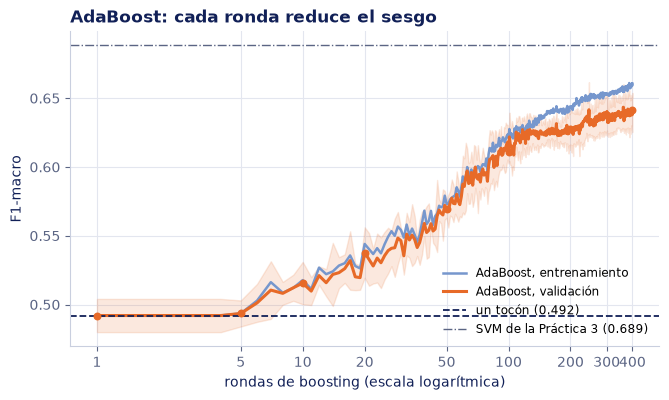

Tocón: F1-macro 0.4920 en validación y 0.4920 en entrenamiento.
AdaBoost con 400 rondas: 0.6416 en validación y 0.6606 en entrenamiento.
Máximo de la curva de validación: 0.6434 en la ronda 361; brecha entrenamiento − validación en la ronda 400: 0.0190.


In [12]:
rondas = np.arange(1, RONDAS + 1)
m_va, s_va, m_tr = curva_ada_va.mean(0), curva_ada_va.std(0), curva_ada_tr.mean(0)
fig, ax = plt.subplots(figsize=(7.6, 4.1))
ax.plot(rondas, m_tr, color=AZUL, linewidth=1.8, label="AdaBoost, entrenamiento")
ax.plot(rondas, m_va, color=NARANJA, linewidth=2.2, label="AdaBoost, validación")
ax.fill_between(rondas, m_va - s_va, m_va + s_va, color=NARANJA, alpha=0.15)
ax.scatter(N_ARBOLES, m_va[idx], color=NARANJA, s=22, zorder=3)
ax.axhline(m_va[0], color=AZUL_OSCURO, linestyle="--", linewidth=1.3, label=f"un tocón ({m_va[0]:.3f})")
ax.axhline(RES["SVM"]["f1"].mean(), color=GRIS, linestyle="-.", linewidth=1,
           label=f"SVM de la Práctica 3 ({RES['SVM']['f1'].mean():.3f})")
ax.set_xscale("log")
ax.set_xticks(N_ARBOLES)
ax.set_xticklabels(N_ARBOLES)
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xlabel("rondas de boosting (escala logarítmica)")
ax.set_ylabel("F1-macro")
ax.set_title("AdaBoost: cada ronda reduce el sesgo")
ax.legend(loc="lower right", fontsize=8.5)
plt.show()

mejor_ronda = int(np.argmax(m_va)) + 1
print(f"Tocón: F1-macro {m_va[0]:.4f} en validación y {m_tr[0]:.4f} en entrenamiento.")
print(f"AdaBoost con 400 rondas: {m_va[-1]:.4f} en validación y {m_tr[-1]:.4f} en entrenamiento.")
print(f"Máximo de la curva de validación: {m_va.max():.4f} en la ronda {mejor_ronda}; "
      f"brecha entrenamiento − validación en la ronda 400: {m_tr[-1] - m_va[-1]:.4f}.")

**¿Qué reduce boosting, y por qué?** Reduce el **sesgo**. El tocón tiene F1-macro de 0.492 **tanto en entrenamiento como en validación**: no sobreajusta, simplemente un corte no alcanza. En los cinco pliegues sus dos hojas predicen solo *Dropout* y *Graduate*, así que la sensibilidad de *Enrolled* es 0. Con cada ronda, AdaBoost sube el F1 de entrenamiento (0.492 → 0.661 en 400 rondas) y el de validación lo sigue de cerca (0.492 → 0.642), con una brecha final de solo 0.019. El modelo se vuelve más expresivo sin sobreajustar.

La razón es que boosting ajusta un **modelo aditivo** por etapas (Friedman, Hastie y Tibshirani, 2000): cada tocón nuevo se entrena con pesos que destacan los errores de los anteriores, así que corrige lo que el conjunto todavía no explica, y la suma de cientos de cortes en atributos distintos forma una frontera que ningún tocón puede formar solo. Es lo opuesto a bagging: el **bagging de 400 tocones da exactamente 0.492**, lo mismo que un tocón, porque todos los bootstrap eligen el mismo corte (no hay varianza que cancelar).

La curva de validación todavía sube lentamente en la ronda 400 (máximo 0.643 en la ronda 361), pero AdaBoost de tocones se queda en 0.642, por debajo de los mejores base: los tocones solo suman efectos de un atributo a la vez y no capturan interacciones, y AdaBoost no tiene pesos por clase (sensibilidad de *Enrolled* 0.27).

In [13]:
def receta_tocon(banco=False):
    cols = COLS_BANCO if banco else COLS_DES
    return Pipeline([("prep", prep_arboles(cols)), ("tocon", DecisionTreeClassifier(max_depth=1, random_state=SEMILLA))])


def receta_adaboost(banco=False):
    cols = COLS_BANCO if banco else COLS_DES
    return Pipeline([("prep", prep_arboles(cols)),
                     ("adaboost", AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=RONDAS,
                                                     learning_rate=1.0, random_state=SEMILLA))])


def receta_bagging_tocones(banco=False):
    cols = COLS_BANCO if banco else COLS_DES
    return Pipeline([("prep", prep_arboles(cols)),
                     ("bagging", BaggingClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=400,
                                                   random_state=SEMILLA, n_jobs=1))])


RECETAS["Tocón (profundidad 1)"] = receta_tocon
RECETAS["AdaBoost (400 tocones)"] = receta_adaboost
RECETAS["Bagging de 400 tocones"] = receta_bagging_tocones
registrar(RES, "Tocón (profundidad 1)", "Boosting", receta_tocon, X, y, PLIEGUES, SCORING_DES,
          config="un corte")
registrar(RES, "AdaBoost (400 tocones)", "Boosting", receta_adaboost, X, y, PLIEGUES, SCORING_DES,
          config="400 rondas, learning_rate=1 (SAMME)")
registrar(RES, "Bagging de 400 tocones", "Bagging", receta_bagging_tocones, X, y, PLIEGUES, SCORING_DES,
          config="contraste: bagging no reduce sesgo")

Tocón (profundidad 1)                                F1-macro 0.4920 ± 0.0121 | sens. 0.000 | 0.01 s por pliegue


AdaBoost (400 tocones)                               F1-macro 0.6416 ± 0.0122 | sens. 0.266 | 1.59 s por pliegue


Bagging de 400 tocones                               F1-macro 0.4920 ± 0.0121 | sens. 0.000 | 1.14 s por pliegue


---

## 1.3 Combinar los cinco clasificadores base

Se combinan los cinco clasificadores de la Práctica 3, cada uno con su propio preprocesamiento dentro de su `Pipeline`:

- **Votación dura:** cada clasificador vota por una clase y gana la mayoría (con empate, la de menor índice).
- **Votación suave:** se promedian las probabilidades de los cinco y se elige la clase con mayor promedio.
- **Stacking:** las probabilidades de los cinco, obtenidas con validación cruzada **interna** (5 pliegues dentro de cada partición de entrenamiento), son la entrada de un meta-modelo logístico que aprende cuánto confiar en cada uno y en qué clase (Wolpert, 1992).

El SVC no produce probabilidades, así que en la votación suave y en el *stacking* se envuelve con `CalibratedClassifierCV` (calibración sigmoide de Platt con 5 pliegues). Como el ensamble completo se entrena dentro de cada pliegue de `cross_validate`, la calibración se hace **solo con la partición de entrenamiento** de ese pliegue. Los tres se evalúan con `cross_validate` y los mismos cinco pliegues.

In [14]:
def estimadores_base(banco=False, calibrar_svm=False):
    lista = []
    for n in BASES:
        m = base(n, banco)
        if n == "SVM" and calibrar_svm:
            m = CalibratedClassifierCV(m, method="sigmoid",
                                       cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA))
        lista.append((ALIAS[n], m))
    return lista


def receta_voto_duro(banco=False):
    return VotingClassifier(estimadores_base(banco), voting="hard")


def receta_voto_suave(banco=False):
    return VotingClassifier(estimadores_base(banco, calibrar_svm=True), voting="soft")


def receta_stacking(banco=False):
    return StackingClassifier(estimadores_base(banco, calibrar_svm=True),
                              final_estimator=LogisticRegression(max_iter=1000),
                              cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA),
                              stack_method="predict_proba")


RECETAS["Votación dura (5 base)"] = receta_voto_duro
RECETAS["Votación suave (5 base, SVM calibrado)"] = receta_voto_suave
def receta_stacking_pesos(banco=False):
    return StackingClassifier(estimadores_base(banco, calibrar_svm=True),
                              final_estimator=LogisticRegression(max_iter=1000, class_weight="balanced"),
                              cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA),
                              stack_method="predict_proba")


RECETAS["Stacking (5 base → logística)"] = receta_stacking
RECETAS["Stacking (5 base → logística con pesos balanced)"] = receta_stacking_pesos
registrar(RES, "Votación dura (5 base)", "Combinación", receta_voto_duro, X, y, PLIEGUES, SCORING_DES,
          config="mayoría de los 5")
registrar(RES, "Votación suave (5 base, SVM calibrado)", "Combinación", receta_voto_suave, X, y, PLIEGUES,
          SCORING_DES, config="promedio de probabilidades; SVM con calibración sigmoide (5 pliegues internos)")
registrar(RES, "Stacking (5 base → logística)", "Combinación", receta_stacking, X, y, PLIEGUES, SCORING_DES,
          config="meta-modelo LogisticRegression sobre probabilidades de 5 pliegues internos")
registrar(RES, "Stacking (5 base → logística con pesos balanced)", "Combinación", receta_stacking_pesos, X, y,
          PLIEGUES, SCORING_DES, config="igual, con class_weight=balanced en el meta-modelo")

Votación dura (5 base)                               F1-macro 0.6909 ± 0.0070 | sens. 0.512 | 1.41 s por pliegue


Votación suave (5 base, SVM calibrado)               F1-macro 0.6760 ± 0.0050 | sens. 0.422 | 2.66 s por pliegue


Stacking (5 base → logística)                        F1-macro 0.6745 ± 0.0142 | sens. 0.362 | 13.89 s por pliegue


Stacking (5 base → logística con pesos balanced)     F1-macro 0.6919 ± 0.0067 | sens. 0.603 | 13.13 s por pliegue


### ¿Qué tan correlacionados están los errores de los cinco?

Un ensamble solo gana si sus miembros se equivocan **en estudiantes distintos**. Con las predicciones de validación cruzada de cada clasificador (mismos pliegues) se construye, para cada uno, un indicador de error por estudiante (1 si se equivoca) y se calcula:

- la correlación entre los indicadores de error de cada par de clasificadores (coeficiente φ),
- cuántos clasificadores fallan en cada estudiante, comparado con lo que se esperaría si los errores fueran independientes con las mismas tasas (distribución binomial de Poisson),
- el **oráculo**: la fracción de estudiantes que al menos uno de los cinco clasifica bien, que es el techo de cualquier combinación de sus predicciones.

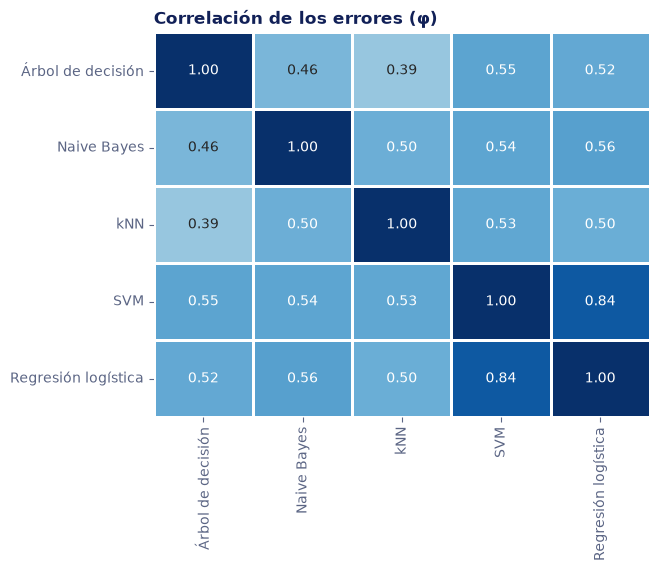

,observado,si fueran independientes
fallan 0 de 5,0.481,0.175
fallan 1 de 5,0.157,0.366
fallan 2 de 5,0.091,0.305
fallan 3 de 5,0.072,0.126
fallan 4 de 5,0.082,0.026
fallan 5 de 5,0.118,0.002


Tasa de error de cada clasificador: {'Árbol de decisión': 0.323, 'Naive Bayes': 0.32, 'kNN': 0.296, 'SVM': 0.262, 'Regresión logística': 0.268}
Correlación media entre pares: 0.54 (de 0.39 a 0.84)
Par más correlacionado: SVM y Regresión logística (0.84); menos correlacionado: Árbol de decisión y kNN (0.39)
Los cinco fallan a la vez en 11.8% de los estudiantes (con independencia serían 0.2%).
Mayoría equivocada (3 o más fallan): 27.1% observado contra 15.5% con independencia.
Oráculo (al menos uno acierta): 88.2% | F1-macro de la votación por mayoría: 0.6913


In [15]:
OOF = {n: cross_val_predict(base(n), X, y, cv=PLIEGUES, n_jobs=-1) for n in BASES}
E = pd.DataFrame({n: (OOF[n] != y).astype(int) for n in BASES})

corr_err = E.corr()
fig, ax = plt.subplots(figsize=(6.4, 5))
sns.heatmap(corr_err, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, linewidths=1, ax=ax)
ax.set_title("Correlación de los errores (φ)")
ax.grid(False)
plt.show()

fallan = E.sum(axis=1).to_numpy()
dist_indep = np.array([1.0])
for p in E.mean():
    dist_indep = np.convolve(dist_indep, [1 - p, p])
obs = np.bincount(fallan, minlength=6) / len(fallan)
display(pd.DataFrame({"observado": obs, "si fueran independientes": dist_indep},
                     index=[f"fallan {i} de 5" for i in range(6)]).round(3))

voto_oof = np.array([np.bincount(f, minlength=3).argmax() for f in np.column_stack([OOF[n] for n in BASES])])
pares = corr_err.where(~np.eye(5, dtype=bool)).stack()
print("Tasa de error de cada clasificador:", E.mean().round(3).to_dict())
print(f"Correlación media entre pares: {pares.mean():.2f} (de {pares.min():.2f} a {pares.max():.2f})")
print(f"Par más correlacionado: {' y '.join(pares.idxmax())} ({pares.max():.2f}); "
      f"menos correlacionado: {' y '.join(pares.idxmin())} ({pares.min():.2f})")
print(f"Los cinco fallan a la vez en {obs[5]:.1%} de los estudiantes (con independencia serían {dist_indep[5]:.1%}).")
print(f"Mayoría equivocada (3 o más fallan): {obs[3:].sum():.1%} observado contra {dist_indep[3:].sum():.1%} con independencia.")
print(f"Oráculo (al menos uno acierta): {1 - obs[5]:.1%} | F1-macro de la votación por mayoría: {f1m(y, voto_oof):.4f}")

**Lectura e implicaciones.** Los errores están **fuertemente correlacionados**: la correlación media entre pares es 0.54, y **los cinco fallan a la vez en 11.8 % de los estudiantes**, cuando con errores independientes (y las mismas tasas de error, de 0.26 a 0.32) serían 0.2 %. La mayoría se equivoca en 27.1 % de los estudiantes, contra 15.5 % con independencia. La razón está en la Práctica 3: los errores se concentran en estudiantes que los atributos del primer semestre no distinguen (inscritos con desempeño intermedio y desertores con buenas calificaciones), y ningún clasificador puede separarlos, sin importar su sesgo inductivo.

El par más correlacionado es **SVM y regresión logística (0.84)**, que usan la misma representación (one-hot y escalado) y fronteras casi lineales: combinarlos es casi como tener dos votos del mismo modelo. El menos correlacionado es **árbol y kNN (0.39)**, que miran los datos de forma muy distinta, pero son de los más débiles.

**Lo que implica**, visto en las cuatro combinaciones:

- **Votación dura (0.6909):** apenas +0.002 sobre el SVM. Con errores tan correlacionados, la mayoría casi nunca corrige al mejor; en la práctica reproduce sus predicciones.
- **Votación suave (0.6760) y stacking con meta-modelo logístico simple (0.6745):** quedan **por debajo** del SVM. Al promediar probabilidades (o al aprender una regresión logística sin pesos sobre ellas) se pierde el refuerzo de *Enrolled* que cada base tenía en su regla de decisión: la sensibilidad de *Enrolled* cae a 0.42 y 0.36. No es un problema de los errores sino de **dónde queda la frontera**.
- **Stacking con pesos `balanced` en el meta-modelo (0.6919):** al devolver el peso a *Enrolled*, su sensibilidad sube a 0.60 y el F1-macro supera ligeramente al SVM (+0.003).

El oráculo (88.2 % de estudiantes en los que al menos uno acierta) es un techo inalcanzable, porque no se sabe de antemano cuál clasificador acertará.

---

## 1.4 Bagging optimizado: Random Forest y Extra-Trees

Random Forest (Breiman, 2001) agrega a bagging un **sorteo de atributos en cada corte** (`max_features`), y Extra-Trees (Geurts *et al.*, 2006) además sortea el **umbral** del corte y, por omisión, no usa bootstrap. Ambos bajan la correlación $\rho$ entre árboles, que es lo que limitaba a bagging. Se usan 300 árboles (la curva de la sección 1.1 ya es plana desde unos 200) y `RandomizedSearchCV` con 50 configuraciones y los mismos cinco pliegues:

| Hiperparámetro | Valores |
|---|---|
| Codificación de los nominales | ordinal, one-hot (< 10 agrupadas) o one-hot (< 30 agrupadas) |
| `max_features` | `sqrt`, `log2`, 0.2, 0.3, 0.5, 0.7 |
| `min_samples_leaf` | entero entre 1 y 30 |
| `max_depth` | sin límite, 6, 8, 10, 14, 20 |
| `criterion` | `gini`, `entropy`, `log_loss` |
| `class_weight` | ninguno, `balanced`, `balanced_subsample`, Enrolled ×2, Enrolled ×3 |
| `max_samples` (tamaño del bootstrap) | completo, 50 %, 70 %, 90 % |
| `bootstrap` (solo Extra-Trees) | sí o no (sin bootstrap no aplica `max_samples`) |

50 configuraciones (50 distintas) en 31 s | mejor f1_macro: 0.6825 (configuración 37)


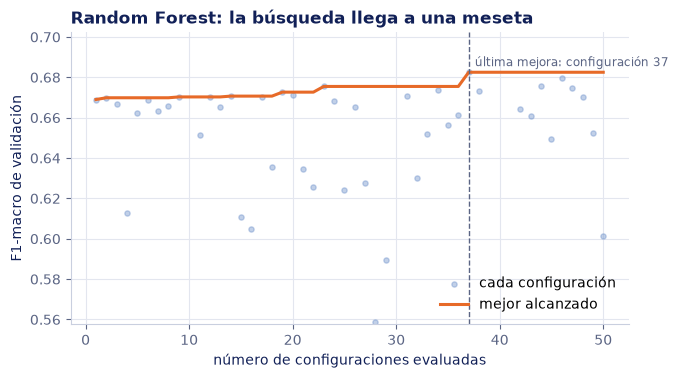

Mejor: 0.6825 | a la mitad (25 configuraciones) ya se tenía 0.6755 | mejora en la segunda mitad: +0.0070
Mejor configuración: class_weight=balanced_subsample, criterion=log_loss, max_depth=10, max_features=0.3, max_samples=0.7, min_samples_leaf=4, nominales=one-hot (min_freq=30)


In [16]:
N_ITER = 50
CODIFICACIONES = [ordinal(), onehot(10), onehot(30)]
PESOS = [None, "balanced", {0: 1.0, 1: 2.0, 2: 1.0}, {0: 1.0, 1: 3.0, 2: 1.0}]


def pipe_arboles(cols, clf):
    return Pipeline([("prep", ColumnTransformer([("nom", ordinal(), cols["nom"])], remainder="passthrough")),
                     ("clf", clf)])


def pipe_rf(cols):
    return pipe_arboles(cols, RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=1))


def pipe_et(cols):
    return pipe_arboles(cols, ExtraTreesClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=1))


def receta_desde_params(constructor, params):
    """Receta que reconstruye la mejor configuración de una búsqueda (también en Bank Marketing)."""
    def receta(banco=False):
        cols = COLS_BANCO if banco else COLS_DES
        p = traducir(params) if banco else params
        return constructor(cols).set_params(**{k: clone(v) if hasattr(v, "get_params") else v for k, v in p.items()})
    return receta


base_bosque = {"prep__nom": CODIFICACIONES,
               "clf__max_features": ["sqrt", "log2", 0.2, 0.3, 0.5, 0.7],
               "clf__min_samples_leaf": randint(1, 31),
               "clf__max_depth": [None, 6, 8, 10, 14, 20],
               "clf__criterion": ["gini", "entropy", "log_loss"],
               "clf__class_weight": PESOS + ["balanced_subsample"]}
ESPACIO_RF = dict(base_bosque, clf__max_samples=[None, 0.5, 0.7, 0.9])
ESPACIO_ET = [dict(base_bosque, clf__bootstrap=[False]),
              dict(base_bosque, clf__bootstrap=[True], clf__max_samples=[None, 0.5, 0.7, 0.9])]

cvr_rf, i_rf = buscar(pipe_rf(COLS_DES), ESPACIO_RF, X, y, PLIEGUES, SCORING_DES, N_ITER)
RECETAS["Random Forest (optimizado)"] = receta_desde_params(pipe_rf, cvr_rf.loc[i_rf, "params"])
registrar_busqueda(RES, "Random Forest (optimizado)", "Bagging", cvr_rf, i_rf, RECETAS["Random Forest (optimizado)"])
graficar_meseta(cvr_rf, "Random Forest: la búsqueda llega a una meseta")
print("Mejor configuración:", RES["Random Forest (optimizado)"]["config"])

50 configuraciones (50 distintas) en 22 s | mejor f1_macro: 0.6784 (configuración 34)


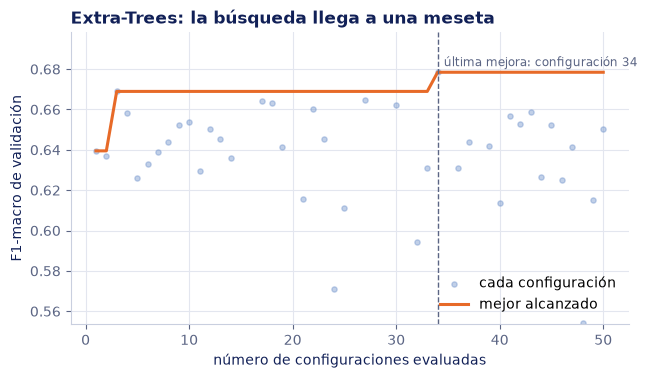

Mejor: 0.6784 | a la mitad (25 configuraciones) ya se tenía 0.6689 | mejora en la segunda mitad: +0.0095
Mejor configuración: bootstrap=False, class_weight=balanced_subsample, criterion=entropy, max_depth=20, max_features=0.7, min_samples_leaf=11, nominales=one-hot (min_freq=30)


In [17]:
cvr_et, i_et = buscar(pipe_et(COLS_DES), ESPACIO_ET, X, y, PLIEGUES, SCORING_DES, N_ITER)
RECETAS["Extra-Trees (optimizado)"] = receta_desde_params(pipe_et, cvr_et.loc[i_et, "params"])
registrar_busqueda(RES, "Extra-Trees (optimizado)", "Bagging", cvr_et, i_et, RECETAS["Extra-Trees (optimizado)"])
graficar_meseta(cvr_et, "Extra-Trees: la búsqueda llega a una meseta")
print("Mejor configuración:", RES["Extra-Trees (optimizado)"]["config"])

In [18]:
def efecto(cvr, parametro, nombre):
    """Mejor y mediana del F1-macro según el valor de un hiperparámetro."""
    col = cvr["params"].map(lambda p: formatear({parametro: p.get(parametro, "—")}).split("=", 1)[1])
    return (cvr.assign(valor=col).groupby("valor")["mean_test_f1_macro"]
            .agg(configuraciones="size", mejor="max", mediana="median").round(4)
            .sort_values("mejor", ascending=False).rename_axis(nombre))


display(efecto(cvr_rf, "clf__class_weight", "RF: class_weight"))
display(efecto(cvr_rf, "clf__max_features", "RF: max_features"))
display(efecto(cvr_et, "clf__bootstrap", "ET: bootstrap"))

,configuraciones,mejor,mediana
RF: class_weight,,,
balanced_subsample,12,0.6825,0.6686
"{0: 1.0, 1: 3.0, 2: 1.0}",6,0.6759,0.6696
balanced,5,0.6734,0.6700
"{0: 1.0, 1: 2.0, 2: 1.0}",11,0.6712,0.6683
None,16,0.6566,0.6030


,configuraciones,mejor,mediana
RF: max_features,,,
0.3,11,0.6825,0.6631
sqrt,10,0.6798,0.6630
0.7,7,0.6759,0.6700
0.5,9,0.6755,0.6690
0.2,6,0.6712,0.6521
log2,7,0.6658,0.6344


,configuraciones,mejor,mediana
ET: bootstrap,,,
False,30,0.6784,0.6374
True,20,0.6689,0.6403


**Lectura.** El mejor Random Forest llega a **0.6825 ± 0.0136** (configuración 37: `max_features`=0.3, profundidad 10, ≥ 4 estudiantes por hoja, bootstrap de 70 %, `balanced_subsample`) y el mejor Extra-Trees a **0.6784 ± 0.0061** (configuración 34: sin bootstrap, `max_features`=0.7, ≥ 11 por hoja, `balanced_subsample`). Las dos búsquedas llegan a la meseta: en la segunda mitad mejoran 0.007 y 0.010, menos que la desviación entre pliegues.

Las tablas por hiperparámetro dicen qué importa:

- **Pesos por clase.** Sin pesos, la mediana de Random Forest es 0.603; con cualquier esquema de pesos está entre 0.668 y 0.670. Es la misma lección de la Práctica 3.
- **`max_features`.** Valores intermedios (0.3, `sqrt`) son los mejores; `log2` (unos 5 atributos por corte) es el peor en mediana (0.634): demasiado azar hace árboles débiles.
- **Bootstrap en Extra-Trees.** La mejor configuración no usa bootstrap: la aleatoriedad del umbral ya descorrelaciona los árboles.

Frente al bagging de la sección 1.1 (0.661), Random Forest gana 0.021 al bajar la correlación entre árboles, regular el tamaño de las hojas y usar pesos por clase. Aun así, queda 0.006 por debajo del SVM.

---

## 1.5 Boosting optimizado: XGBoost y LightGBM

XGBoost (Chen y Guestrin, 2016) y LightGBM (Ke *et al.*, 2017) son *gradient boosting*: cada árbol nuevo se ajusta al gradiente de la pérdida logarítmica del ensamble actual, con regularización explícita de las hojas. LightGBM crece los árboles hoja por hoja (`num_leaves`) en lugar de nivel por nivel. Ambos se optimizan con `RandomizedSearchCV`, 50 configuraciones y los mismos pliegues:

| Hiperparámetro | XGBoost | LightGBM |
|---|---|---|
| Codificación de nominales | ordinal, one-hot (< 10) o one-hot (< 30) | igual |
| Número de árboles | 100 a 700 | 100 a 700 |
| Tasa de aprendizaje | 0.01 a 0.3 (log) | 0.01 a 0.3 (log) |
| Tamaño de los árboles | `max_depth` 2 a 8 | `num_leaves` 4 a 63 y `max_depth` (sin límite, 3, 4, 6, 8) |
| Regularización de las hojas | `reg_lambda` (L2) 0.01 a 30, `reg_alpha` (L1) 0.001 a 5, `min_child_weight` 0.5 a 20, `gamma` | `reg_lambda` 0.001 a 30, `reg_alpha` 0.001 a 10, `min_child_samples` 5 a 79 |
| Submuestreo de filas | `subsample` 0.5 a 1 | `subsample` 0.5 a 1 (cada iteración) |
| Submuestreo de columnas | `colsample_bytree` 0.4 a 1 | `colsample_bytree` 0.4 a 1 |
| Pesos por clase | ninguno, `balanced`, Enrolled ×2, ×3 (con `PesosPorClase`) | igual, con `class_weight` |

50 configuraciones (50 distintas) en 25 s | mejor f1_macro: 0.6949 (configuración 38)


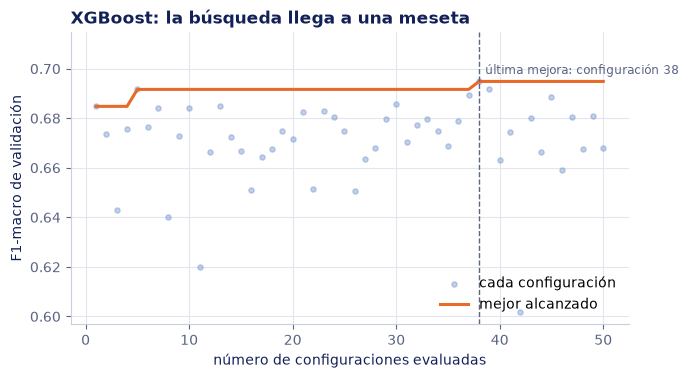

Mejor: 0.6949 | a la mitad (25 configuraciones) ya se tenía 0.6916 | mejora en la segunda mitad: +0.0032
Mejor configuración: class_weight=balanced, colsample_bytree=0.9695, gamma=1, learning_rate=0.01167, max_depth=8, min_child_weight=0.529, n_estimators=541, reg_alpha=0.07134, reg_lambda=0.7507, subsample=0.842, nominales=one-hot (min_freq=30)


In [19]:
def pipe_xgb(cols):
    return pipe_arboles(cols, PesosPorClase(XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEMILLA,
                                                          verbosity=0)))


def pipe_lgbm(cols):
    return pipe_arboles(cols, LGBMClassifier(subsample_freq=1, n_jobs=1, random_state=SEMILLA, verbose=-1))


ESPACIO_XGB = {"prep__nom": CODIFICACIONES,
               "clf__class_weight": PESOS,
               "clf__estimator__n_estimators": randint(100, 701),
               "clf__estimator__learning_rate": loguniform(0.01, 0.3),
               "clf__estimator__max_depth": randint(2, 9),
               "clf__estimator__min_child_weight": loguniform(0.5, 20),
               "clf__estimator__reg_lambda": loguniform(1e-2, 30),
               "clf__estimator__reg_alpha": loguniform(1e-3, 5),
               "clf__estimator__gamma": [0.0, 0.1, 0.5, 1.0],
               "clf__estimator__subsample": uniform(0.5, 0.5),
               "clf__estimator__colsample_bytree": uniform(0.4, 0.6)}

cvr_xgb, i_xgb = buscar(pipe_xgb(COLS_DES), ESPACIO_XGB, X, y, PLIEGUES, SCORING_DES, N_ITER)
RECETAS["XGBoost (optimizado)"] = receta_desde_params(pipe_xgb, cvr_xgb.loc[i_xgb, "params"])
registrar_busqueda(RES, "XGBoost (optimizado)", "Boosting", cvr_xgb, i_xgb, RECETAS["XGBoost (optimizado)"])
graficar_meseta(cvr_xgb, "XGBoost: la búsqueda llega a una meseta")
print("Mejor configuración:", RES["XGBoost (optimizado)"]["config"])

50 configuraciones (50 distintas) en 15 s | mejor f1_macro: 0.6888 (configuración 1)


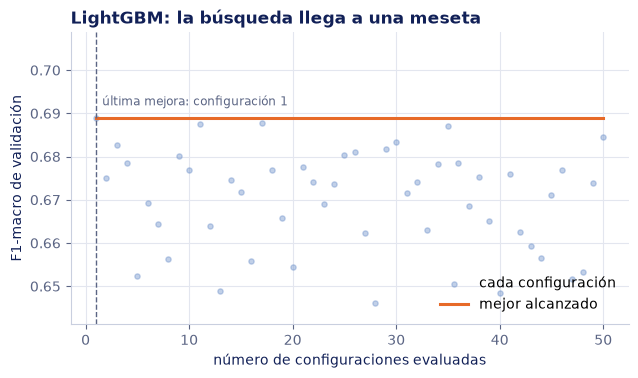

Mejor: 0.6888 | a la mitad (25 configuraciones) ya se tenía 0.6888 | mejora en la segunda mitad: +0.0000
Mejor configuración: class_weight={0: 1.0, 1: 2.0, 2: 1.0}, colsample_bytree=0.8779, learning_rate=0.01866, max_depth=8, min_child_samples=25, n_estimators=221, num_leaves=22, reg_alpha=0.002511, reg_lambda=0.1138, subsample=0.6669, nominales=one-hot (min_freq=30)


In [20]:
ESPACIO_LGBM = {"prep__nom": CODIFICACIONES,
                "clf__class_weight": PESOS,
                "clf__n_estimators": randint(100, 701),
                "clf__learning_rate": loguniform(0.01, 0.3),
                "clf__num_leaves": randint(4, 64),
                "clf__max_depth": [-1, 3, 4, 6, 8],
                "clf__min_child_samples": randint(5, 80),
                "clf__reg_lambda": loguniform(1e-3, 30),
                "clf__reg_alpha": loguniform(1e-3, 10),
                "clf__subsample": uniform(0.5, 0.5),
                "clf__colsample_bytree": uniform(0.4, 0.6)}

cvr_lgbm, i_lgbm = buscar(pipe_lgbm(COLS_DES), ESPACIO_LGBM, X, y, PLIEGUES, SCORING_DES, N_ITER)
RECETAS["LightGBM (optimizado)"] = receta_desde_params(pipe_lgbm, cvr_lgbm.loc[i_lgbm, "params"])
registrar_busqueda(RES, "LightGBM (optimizado)", "Boosting", cvr_lgbm, i_lgbm, RECETAS["LightGBM (optimizado)"])
graficar_meseta(cvr_lgbm, "LightGBM: la búsqueda llega a una meseta")
print("Mejor configuración:", RES["LightGBM (optimizado)"]["config"])

In [21]:
display(efecto(cvr_xgb, "clf__class_weight", "XGBoost: class_weight"))
display(efecto(cvr_lgbm, "clf__class_weight", "LightGBM: class_weight"))
lr_xgb = cvr_xgb["params"].map(lambda p: p["clf__estimator__learning_rate"] * p["clf__estimator__n_estimators"])
print(f"XGBoost: correlación entre (tasa × árboles) y F1-macro: "
      f"{np.corrcoef(np.log(lr_xgb), cvr_xgb['mean_test_f1_macro'])[0, 1]:+.2f}")

,configuraciones,mejor,mediana
XGBoost: class_weight,,,
balanced,17,0.6949,0.6800
"{0: 1.0, 1: 2.0, 2: 1.0}",10,0.6848,0.6737
"{0: 1.0, 1: 3.0, 2: 1.0}",10,0.6841,0.6809
None,13,0.6678,0.6590


,configuraciones,mejor,mediana
LightGBM: class_weight,,,
"{0: 1.0, 1: 2.0, 2: 1.0}",16,0.6888,0.6765
balanced,9,0.6875,0.6803
"{0: 1.0, 1: 3.0, 2: 1.0}",13,0.6810,0.6737
None,12,0.6658,0.6564


XGBoost: correlación entre (tasa × árboles) y F1-macro: +0.22


**Lectura.** XGBoost alcanza **0.6949 ± 0.0126**, el mejor F1-macro de toda la práctica, con la configuración 38: pesos `balanced`, tasa de aprendizaje 0.012 con 541 árboles de profundidad hasta 8, `gamma`=1 y `reg_lambda` ≈ 0.75. Es decir, muchos pasos pequeños con árboles regularizados. LightGBM llega a **0.6888 ± 0.0176** y su mejor configuración fue la primera que se probó: las 49 siguientes no la superaron, una meseta inmediata.

Otra vez, los **pesos por clase** separan a las configuraciones buenas de las malas: sin pesos, el mejor XGBoost llega a 0.668 y el mejor LightGBM a 0.666; con pesos, 0.695 y 0.689. La correlación entre (tasa × número de árboles) y el F1 es débil (+0.22): pasado cierto punto, avanzar más no ayuda, y lo que distingue a las configuraciones es la regularización y los pesos.

---

## 1.6 Todos los modelos de la deserción

La tabla reúne todos los modelos, ordenados por F1-macro (media ± desviación entre los cinco pliegues). La sensibilidad es la de *Enrolled*, la clase más difícil, y el tiempo es el de entrenamiento medio por pliegue (un núcleo). Para los modelos optimizados se reporta la mejor configuración encontrada.

In [22]:
tabla_des = tabla_resultados(RES, "sens. Enrolled")
tabla_des

,familia,F1-macro (media ± desv.),sens. Enrolled,tiempo de entrenamiento (s/pliegue),configuración
modelo,,,,,
XGBoost (optimizado),Boosting,0.6949 ± 0.0126,0.553,3.53,"class_weight=balanced, colsample_bytree=0.9695, gamma=1, learning_rate=0.01167, max_depth=8, min_child_weight=0.529, n_estimators=541, reg_alpha=0.07134, re..."
Stacking (5 base → logística con pesos balanced),Combinación,0.6919 ± 0.0067,0.603,13.13,"igual, con class_weight=balanced en el meta-modelo"
Votación dura (5 base),Combinación,0.6909 ± 0.0070,0.512,1.41,mayoría de los 5
LightGBM (optimizado),Boosting,0.6888 ± 0.0176,0.532,0.63,"class_weight={0: 1.0, 1: 2.0, 2: 1.0}, colsample_bytree=0.8779, learning_rate=0.01866, max_depth=8, min_child_samples=25, n_estimators=221, num_leaves=22, r..."
SVM,Base,0.6886 ± 0.0092,0.559,0.32,"C=172.8, gamma=0.0007778, class_weight={0: 1.0, 1: 2.0, 2: 1.0}, min_freq=10"
Random Forest (optimizado),Bagging,0.6825 ± 0.0136,0.518,2.47,"class_weight=balanced_subsample, criterion=log_loss, max_depth=10, max_features=0.3, max_samples=0.7, min_samples_leaf=4, nominales=one-hot (min_freq=30)"
Regresión logística,Base,0.6815 ± 0.0066,0.531,0.98,"C=1.077, l1_ratio=0.3978, class_weight={0: 1.0, 1: 2.0, 2: 1.0}, min_freq=10"
Extra-Trees (optimizado),Bagging,0.6784 ± 0.0061,0.557,4.78,"bootstrap=False, class_weight=balanced_subsample, criterion=entropy, max_depth=20, max_features=0.7, min_samples_leaf=11, nominales=one-hot (min_freq=30)"
"Votación suave (5 base, SVM calibrado)",Combinación,0.6760 ± 0.0050,0.422,2.66,promedio de probabilidades; SVM con calibración sigmoide (5 pliegues internos)


In [23]:
mejor_base = max(BASES, key=lambda n: RES[n]["f1"].mean())
f1_ref = RES[mejor_base]["f1"]
ganancias_des = pd.DataFrame([{
    "modelo": n, "familia": d["familia"],
    f"ΔF1 contra {mejor_base} (media)": (d["f1"] - f1_ref).mean(),
    "desv. de la diferencia": (d["f1"] - f1_ref).std(),
    "pliegues en que gana": int(((d["f1"] - f1_ref) > 0).sum()),
} for n, d in RES.items() if n not in BASES]).sort_values(f"ΔF1 contra {mejor_base} (media)", ascending=False)
print(f"Mejor clasificador base: {mejor_base} (F1-macro {f1_ref.mean():.4f}). Diferencias pareadas pliegue a pliegue:")
ganancias_des.set_index("modelo").round(4)

Mejor clasificador base: SVM (F1-macro 0.6886). Diferencias pareadas pliegue a pliegue:


,familia,ΔF1 contra SVM (media),desv. de la diferencia,pliegues en que gana
modelo,,,,
XGBoost (optimizado),Boosting,0.0063,0.0144,3
Stacking (5 base → logística con pesos balanced),Combinación,0.0033,0.0095,3
Votación dura (5 base),Combinación,0.0023,0.0087,2
LightGBM (optimizado),Boosting,0.0003,0.0136,2
Random Forest (optimizado),Bagging,-0.0061,0.0152,2
Extra-Trees (optimizado),Bagging,-0.0101,0.0124,1
"Votación suave (5 base, SVM calibrado)",Combinación,-0.0126,0.0115,1
Stacking (5 base → logística),Combinación,-0.0140,0.0167,1
Bagging (400 árboles sin límite),Bagging,-0.0275,0.0231,1


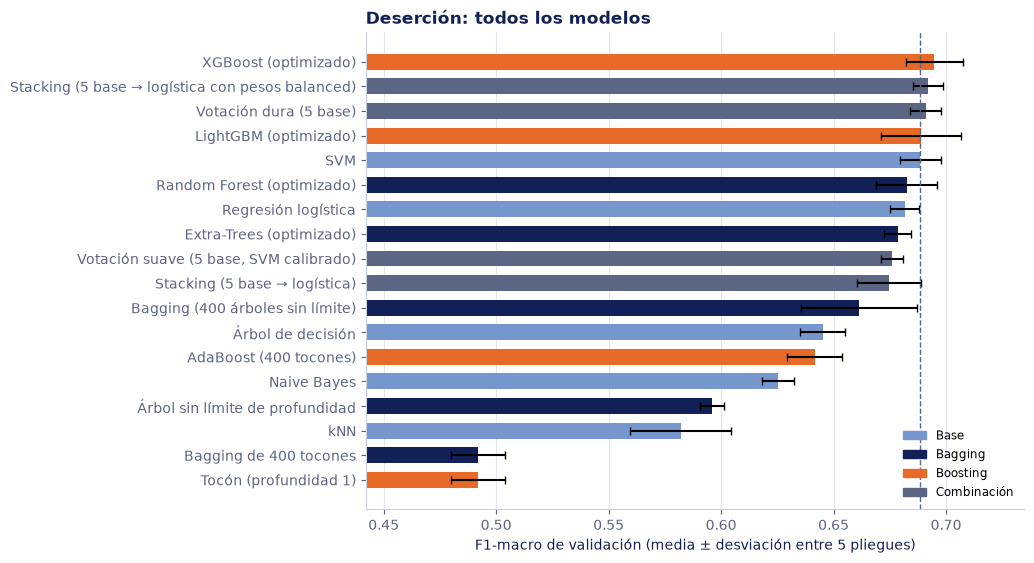

In [24]:
fig, ax = plt.subplots(figsize=(8.5, 6.2))
orden = tabla_des.index[::-1]
medias = [RES[n]["f1"].mean() for n in orden]
desv = [RES[n]["f1"].std() for n in orden]
colores = {"Base": AZUL, "Bagging": AZUL_OSCURO, "Boosting": NARANJA, "Combinación": GRIS}
ax.barh(orden, medias, xerr=desv, color=[colores[RES[n]["familia"]] for n in orden], capsize=3, height=0.65)
ax.axvline(f1_ref.mean(), color=GRIS, linestyle="--", linewidth=1)
ax.set_xlim(max(0, min(medias) - 0.05), max(medias) + 0.04)
ax.set_xlabel("F1-macro de validación (media ± desviación entre 5 pliegues)")
ax.set_title("Deserción: todos los modelos")
ax.grid(axis="y", visible=False)
ax.legend(handles=[matplotlib.patches.Patch(color=c, label=fam) for fam, c in colores.items()],
          loc="lower right", fontsize=8.5)
plt.show()

### Matriz de confusión del mejor modelo

Se calcula con las predicciones de validación cruzada (`cross_val_predict`, mismos pliegues) del modelo con mayor F1-macro.

Mejor modelo de la deserción: XGBoost (optimizado) | class_weight=balanced, colsample_bytree=0.9695, gamma=1, learning_rate=0.01167, max_depth=8, min_child_weight=0.529, n_estimators=541, reg_alpha=0.07134, reg_lambda=0.7507, subsample=0.842, nominales=one-hot (min_freq=30)


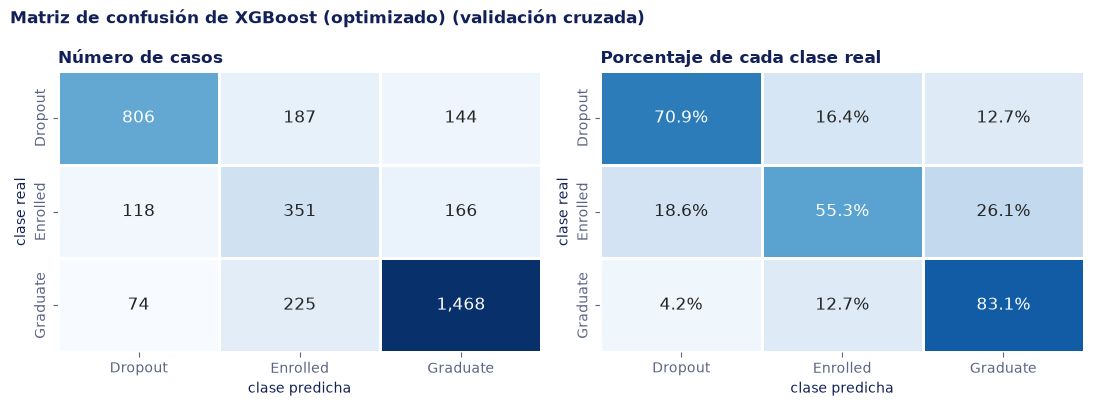

F1-macro de las predicciones agregadas: 0.6951
  sensibilidad de Dropout: 0.709
  sensibilidad de Enrolled: 0.553
  sensibilidad de Graduate: 0.831


In [25]:
mejor_des = tabla_des.index[0]
print("Mejor modelo de la deserción:", mejor_des, "|", RES[mejor_des]["config"])
y_oof_des = cross_val_predict(RECETAS[mejor_des](), X, y, cv=PLIEGUES, n_jobs=-1)
cm_des = graficar_confusion(y, y_oof_des, CLASES, f"Matriz de confusión de {mejor_des} (validación cruzada)")
print(f"F1-macro de las predicciones agregadas: {f1m(y, y_oof_des):.4f}")
for k, c in enumerate(CLASES):
    print(f"  sensibilidad de {c}: {cm_des[k, k] / cm_des[k].sum():.3f}")

**¿Cuánto ganan los ensambles?** La tabla de diferencias pareadas responde la pregunta de la práctica: cada fila es el F1-macro de un ensamble menos el del SVM **en el mismo pliegue**, con la desviación de esa diferencia y el número de pliegues en que gana.

- **Contra base bien ajustados, casi nada.** Solo cuatro ensambles superan al SVM, y por muy poco: XGBoost +0.006, el *stacking* con pesos +0.003, la votación dura +0.002 y LightGBM +0.0003. En los cuatro, la desviación de la diferencia (0.009 a 0.014) es **mayor que la ganancia**, y ninguno gana en más de 3 de los 5 pliegues. Random Forest, Extra-Trees, la votación suave y el *stacking* sin pesos quedan por debajo. Ninguna ganancia es distinguible del ruido entre pliegues.
- **Contra base débiles, mucho.** Bagging sube el árbol sin límite de 0.596 a 0.661 (+0.065) y AdaBoost sube el tocón de 0.492 a 0.642 (+0.150). Los ensambles corrigen bien la varianza o el sesgo de un modelo **mal** ajustado; el SVM optimizado ya no tiene mucho de ninguno de los dos.
- **El costo sí cambia mucho:** el SVM se entrena en 0.3 s por pliegue; XGBoost en 3.6 s y el *stacking* en 14 s, para una ganancia que no se puede distinguir de cero.

El mejor modelo, XGBoost, tiene un perfil algo distinto al del SVM (sensibilidad de *Dropout* 0.71 contra 0.65, *Enrolled* 0.55 contra 0.56, *Graduate* 0.83 contra 0.86), pero comete en esencia los mismos errores: *Enrolled* sigue siendo la clase que se confunde. El techo cercano a 0.69 de la Práctica 3 es **error irreducible** con la información del primer semestre, y ningún ensamble crea información que no está en los atributos.

---

## 1.7 El mejor modelo de la deserción en Bank Marketing

Se toma la **receta** del mejor modelo de la deserción (el mismo tipo de modelo, el mismo preprocesamiento por grupo de columnas y los mismos hiperparámetros) y se aplica a Bank Marketing (Tarea 4) sin volver a optimizarla. Los únicos cambios son los inevitables: las columnas (10 categóricas en el lugar de los nominales y 9 numéricas), los pesos por clase de tres a dos clases (*Enrolled* ×k pasa a *yes* ×k) y, si interviene el SVM, la aproximación de Nyström. Como comparación se aplica también la receta del mejor clasificador base, y la línea base de responder siempre «no».

Se usa `bank-additional-full.csv` sin `duration` (solo se conoce cuando la llamada ya terminó; Tarea 4), con `y` = 1 para *yes* y 0 para *no*, y se evalúa con `StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)`.

In [26]:
banco = pd.read_csv("bank-additional-full.csv", sep=";")
X_b = banco.drop(columns=["duration", "y"])
y_b = (banco["y"] == "yes").astype(int).to_numpy()
CAT_B = X_b.select_dtypes(exclude="number").columns.tolist()
NUM_B = X_b.select_dtypes(include="number").columns.tolist()
COLS_BANCO = {"nom": CAT_B, "bin": [], "num": NUM_B}

CV_BANCO = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_BANCO)
SCORING_B = {"f1_macro": "f1_macro", "sens": make_scorer(recall_score)}      # sensibilidad de yes (clase 1)
CLASES_B = ["no", "yes"]

print(f"{X_b.shape[0]} clientes × {X_b.shape[1]} atributos | yes: {y_b.mean():.2%}")
print("Categóricos:", CAT_B)
print("Numéricos:  ", NUM_B)

RES_B = {}
registrar(RES_B, "Siempre «no» (línea base)", "Línea base", lambda: DummyClassifier(strategy="most_frequent"),
          X_b, y_b, CV_BANCO, SCORING_B, config="clase mayoritaria")
for n in dict.fromkeys([mejor_des, mejor_base]):         # sin repetir si el mejor es un base
    registrar(RES_B, f"{n} (receta de la deserción)", RES[n]["familia"], partial(RECETAS[n], banco=True),
              X_b, y_b, CV_BANCO, SCORING_B, config=f"sin reoptimizar: {RES[n]['config']}")

tabla_resultados(RES_B, "sens. yes")

41188 clientes × 19 atributos | yes: 11.27%
Categóricos: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numéricos:   ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


Siempre «no» (línea base)                            F1-macro 0.4702 ± 0.0000 | sens. 0.000 | 0.01 s por pliegue

XGBoost (optimizado) (receta de la deserción)        F1-macro 0.6974 ± 0.0047 | sens. 0.604 | 3.56 s por pliegue


SVM (receta de la deserción)                         F1-macro 0.6951 ± 0.0069 | sens. 0.406 | 24.63 s por pliegue


,familia,F1-macro (media ± desv.),sens. yes,tiempo de entrenamiento (s/pliegue),configuración
modelo,,,,,
XGBoost (optimizado) (receta de la deserción),Boosting,0.6974 ± 0.0047,0.604,3.56,"sin reoptimizar: class_weight=balanced, colsample_bytree=0.9695, gamma=1, learning_rate=0.01167, max_depth=8, min_child_weight=0.529, n_estimators=541, reg_..."
SVM (receta de la deserción),Base,0.6951 ± 0.0069,0.406,24.63,"sin reoptimizar: C=172.8, gamma=0.0007778, class_weight={0: 1.0, 1: 2.0, 2: 1.0}, min_freq=10"
Siempre «no» (línea base),Línea base,0.4702 ± 0.0000,0.000,0.01,clase mayoritaria


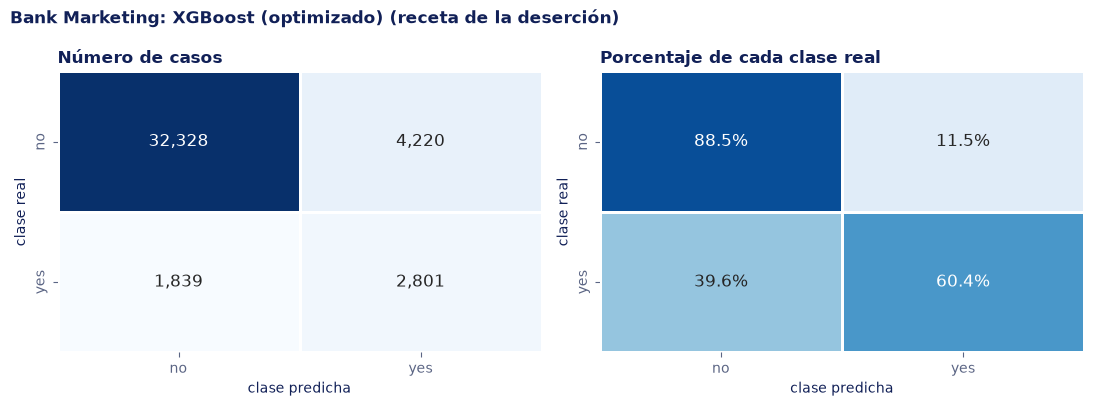

Predice yes para 17.0% de los clientes (la tasa real es 11.3%).


In [27]:
nombre_tr = f"{mejor_des} (receta de la deserción)"
y_oof_tr = cross_val_predict(RECETAS[mejor_des](banco=True), X_b, y_b, cv=CV_BANCO, n_jobs=-1)
graficar_confusion(y_b, y_oof_tr, CLASES_B, f"Bank Marketing: {nombre_tr}")
print(f"Predice yes para {y_oof_tr.mean():.1%} de los clientes (la tasa real es {y_b.mean():.1%}).")

**¿Funcionó lo mismo que en la deserción, y por qué?** Funcionó a medias. La receta de XGBoost llega a **0.6974 ± 0.0047** en Bank Marketing, muy por encima de responder siempre «no» (0.470) y por encima de la receta del SVM (0.6951), pero, como se ve en la Parte 2, queda 0.021 por debajo del mejor modelo reoptimizado para este problema (0.7187).

La razón principal es **dónde queda la frontera**. En la deserción, los pesos `balanced` equilibraban tres clases con un desbalance moderado (la menor es el 18 %); en Bank Marketing, `balanced` multiplica el peso de *yes* por casi 8, y el modelo se va al extremo contrario: predice *yes* para el **17.0 %** de los clientes cuando solo acepta el 11.3 %. Gana sensibilidad (0.60), pero hace muchas llamadas inútiles. La receta del SVM tiene el problema opuesto: con *yes* ×2 queda conservadora (sensibilidad 0.41). Ninguna de las dos fronteras fue elegida para este problema; la Parte 2 la ajusta directamente con el umbral.

Hay un detalle a favor de XGBoost: un ensamble de árboles se traslada mejor que el SVM, porque no depende de la escala de los atributos ni de un `gamma` elegido para otra cantidad de columnas. Además, el SVM aproximado tarda 25 s por pliegue contra 4 s de XGBoost.

Además, los atributos son de otra naturaleza: en la deserción la señal es casi lineal y está concentrada en el desempeño académico; en Bank Marketing está en indicadores macroeconómicos con pocos valores distintos (que funcionan como un reloj de la campaña), en el resultado de campañas anteriores y en interacciones entre ellos. Por eso la Parte 2 vuelve a buscar el modelo: el preprocesamiento, el balanceo de clases y, sobre todo, el **umbral** se deben ajustar a este problema.

---

# Parte 2. Bank Marketing

## 2.1 Protocolo

- **Datos:** `bank-additional-full.csv` (41,188 clientes) sin `duration`; `X` es el archivo sin `duration` ni `y`, y `y` vale 1 (*yes*) o 0 (*no*).
- **Evaluación:** el F1-macro de cada modelo sale de `cross_validate(modelo, X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2026), scoring=...)`. La función `registrar` pide a la vez `"f1_macro"` y la sensibilidad de *yes*; el F1-macro es exactamente el de `scoring="f1_macro"` (al final se comprueba con la llamada literal para el modelo elegido).
- **Todo dentro del modelo:** el preprocesamiento, el balanceo y el **umbral** van dentro de un `Pipeline` o de un meta-estimador, de modo que se ajustan solo con los pliegues de entrenamiento. El umbral se ajusta con `TunedThresholdClassifierCV`, que elige el umbral que maximiza el F1-macro con una validación cruzada **interna** (3 pliegues estratificados del entrenamiento) y después reentrena el modelo con todo el pliegue.
- **Optimización:** las búsquedas aleatorias usan los mismos 5 pliegues y escogen por **precisión promedio** (área bajo la curva de precisión contra sensibilidad), que mide qué tan bien ordena el modelo a los clientes sin depender del umbral; el umbral se ajusta después, dentro del modelo.
- **Balanceo de clases:** se comparan tres estrategias que no inventan datos: pesos por clase (`class_weight`, `scale_pos_weight`), ajuste del umbral, y ambas.

Que la búsqueda y la comparación usen los mismos pliegues hace que la mejor configuración sea un poco optimista (como en la Práctica 3); con 41 mil clientes ese sesgo es pequeño.

## 2.2 Preprocesamiento y modelos lineales

Dos preprocesamientos para los modelos lineales:

- **Tarea 4:** one-hot de las categóricas y escalado estándar de las numéricas.
- **Nuevo:** además, `pdays` se trata como categórica (el 96 % vale 999, «nunca contactado», que como número es un valor extremo sin sentido), y `campaign` y `previous`, muy sesgadas, se transforman con $\log(1+x)$ antes de escalar. Las categorías con menos de 20 clientes se agrupan.

Para los árboles, las categóricas se codifican como ordinales y lo demás pasa tal cual.

In [28]:
LOG_B = ["campaign", "previous"]
ESC_B = [c for c in NUM_B if c not in LOG_B + ["pdays"]]


def prep_lineal_tarea4():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_B),
                              ("num", StandardScaler(), NUM_B)])


def prep_lineal():
    return ColumnTransformer([
        ("cat", onehot(20), CAT_B),
        ("pdays", onehot(20), ["pdays"]),
        ("log", Pipeline([("log1p", FunctionTransformer(np.log1p)), ("esc", StandardScaler())]), LOG_B),
        ("num", StandardScaler(), ESC_B)])


def prep_arboles_b():
    return ColumnTransformer([("cat", ordinal(), CAT_B)], remainder="passthrough")


def con_umbral(modelo):
    """El umbral que maximiza el F1-macro se elige con 3 pliegues internos del entrenamiento."""
    return TunedThresholdClassifierCV(modelo, scoring="f1_macro",
                                      cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA))


def logistica(**kw):
    return LogisticRegression(max_iter=2000, **kw)


registrar(RES_B, "Regresión logística (preproc. Tarea 4)", "Base",
          lambda: Pipeline([("prep", prep_lineal_tarea4()), ("clf", logistica())]),
          X_b, y_b, CV_BANCO, SCORING_B, config="C=1, umbral 0.5")
registrar(RES_B, "Regresión logística (preproc. nuevo)", "Base",
          lambda: Pipeline([("prep", prep_lineal()), ("clf", logistica())]),
          X_b, y_b, CV_BANCO, SCORING_B, config="C=1, umbral 0.5")
registrar(RES_B, "Regresión logística (preproc. nuevo, pesos balanced)", "Base",
          lambda: Pipeline([("prep", prep_lineal()), ("clf", logistica(class_weight="balanced"))]),
          X_b, y_b, CV_BANCO, SCORING_B, config="C=1, class_weight=balanced, umbral 0.5")
registrar(RES_B, "Regresión logística (preproc. nuevo) + umbral", "Base",
          lambda: con_umbral(Pipeline([("prep", prep_lineal()), ("clf", logistica())])),
          X_b, y_b, CV_BANCO, SCORING_B, config="C=1, umbral ajustado por F1-macro (CV interna)")

Regresión logística (preproc. Tarea 4)               F1-macro 0.6419 ± 0.0099 | sens. 0.228 | 0.38 s por pliegue


Regresión logística (preproc. nuevo)                 F1-macro 0.6403 ± 0.0098 | sens. 0.224 | 0.68 s por pliegue


Regresión logística (preproc. nuevo, pesos balanced) F1-macro 0.6743 ± 0.0042 | sens. 0.628 | 0.80 s por pliegue


Regresión logística (preproc. nuevo) + umbral        F1-macro 0.7070 ± 0.0062 | sens. 0.511 | 2.16 s por pliegue


**Lectura.** Estas cuatro filas separan los efectos:

- **Preprocesamiento:** el nuevo no mejora al de la Tarea 4 (0.6403 contra 0.6419). La regresión logística ya veía la señal de `pdays` a través de `poutcome` y `previous`, que dicen lo mismo («contactado antes, y con qué resultado»).
- **Pesos `balanced`:** 0.6743. La sensibilidad de *yes* salta de 0.22 a 0.63, pero a costa de muchísimas llamadas inútiles.
- **Umbral ajustado:** **0.7070**, +0.067 sobre el mismo modelo con umbral 0.5. La sensibilidad queda en 0.51, en un punto intermedio entre los dos extremos.

Con umbral 0.5 la regresión logística detecta a 22 % de quienes aceptan, igual que en la Tarea 4. En este problema, **el balanceo de clases es sobre todo una cuestión de umbral**: los pesos mueven todas las probabilidades a ciegas; el umbral se elige mirando directamente el F1-macro.

## 2.3 Las recetas de la Práctica 3 en Bank Marketing

Por completitud, los cinco clasificadores base con su receta de la deserción (las que no se evaluaron en la sección 1.7).

In [29]:
for n in BASES:
    nombre = f"{n} (receta de la deserción)"
    if nombre not in RES_B:
        registrar(RES_B, nombre, "Base", partial(RECETAS[n], banco=True), X_b, y_b, CV_BANCO, SCORING_B,
                  config=f"sin reoptimizar: {RES[n]['config']}")

Árbol de decisión (receta de la deserción)           F1-macro 0.6728 ± 0.0176 | sens. 0.634 | 0.40 s por pliegue


Naive Bayes (receta de la deserción)                 F1-macro 0.6785 ± 0.0071 | sens. 0.623 | 0.29 s por pliegue


kNN (receta de la deserción)                         F1-macro 0.6584 ± 0.0071 | sens. 0.284 | 0.25 s por pliegue


Regresión logística (receta de la deserción)         F1-macro 0.6943 ± 0.0069 | sens. 0.405 | 2.44 s por pliegue


## 2.4 Ensambles de árboles optimizados

Se optimizan tres ensambles de árboles con `RandomizedSearchCV` (mismos 5 pliegues, criterio: precisión promedio) y después se les ajusta el umbral dentro del modelo. Random Forest usa 200 árboles y bootstrap de una fracción de las filas para que el costo sea razonable con 33 mil clientes por pliegue. Para el balanceo se incluyen pesos por clase en el espacio (`class_weight` o `scale_pos_weight`, donde 7.9 es la razón *no*/*yes*). AdaBoost de tocones se evalúa como en la Parte 1.

20 configuraciones (20 distintas) en 35 s | mejor ap: 0.4774 (configuración 2)


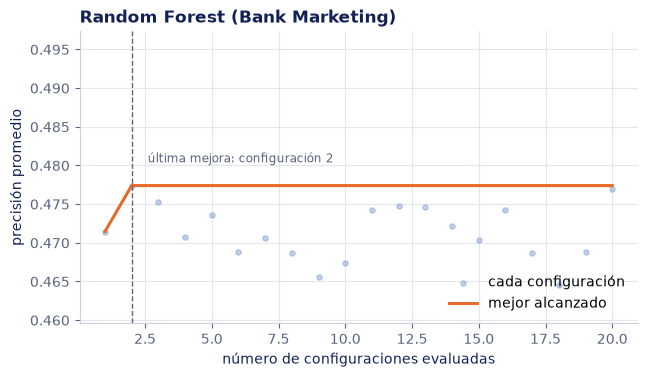

Mejor: 0.4774 | a la mitad (10 configuraciones) ya se tenía 0.4774 | mejora en la segunda mitad: +0.0000


In [30]:
SCORING_BUSQ_B = {"ap": "average_precision", "f1_macro": "f1_macro", "sens": make_scorer(recall_score)}

pipe_rf_b = Pipeline([("prep", prep_arboles_b()),
                      ("clf", RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=SEMILLA))])
ESPACIO_RF_B = {"clf__max_features": ["sqrt", 0.3, 0.5],
                "clf__min_samples_leaf": randint(1, 60),
                "clf__max_depth": [None, 8, 12, 16],
                "clf__criterion": ["gini", "entropy"],
                "clf__class_weight": [None, "balanced", "balanced_subsample", {0: 1.0, 1: 3.0}],
                "clf__max_samples": [0.3, 0.5, 0.8]}
cvr_rf_b, i_rf_b = buscar(pipe_rf_b, ESPACIO_RF_B, X_b, y_b, CV_BANCO, SCORING_BUSQ_B, n_iter=20, criterio="ap")
params_rf_b = cvr_rf_b.loc[i_rf_b, "params"]
graficar_meseta(cvr_rf_b, "Random Forest (Bank Marketing)", criterio="ap", etiqueta="precisión promedio")

30 configuraciones (30 distintas) en 24 s | mejor ap: 0.4790 (configuración 10)


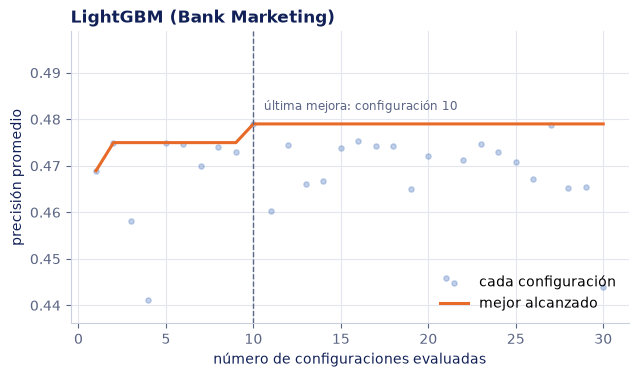

Mejor: 0.4790 | a la mitad (15 configuraciones) ya se tenía 0.4790 | mejora en la segunda mitad: +0.0000


In [31]:
pipe_lgbm_b = Pipeline([("prep", prep_arboles_b()),
                        ("clf", LGBMClassifier(subsample_freq=1, n_jobs=1, random_state=SEMILLA, verbose=-1))])
ESPACIO_LGBM_B = {"clf__n_estimators": randint(100, 801),
                  "clf__learning_rate": loguniform(0.01, 0.2),
                  "clf__num_leaves": randint(8, 128),
                  "clf__max_depth": [-1, 4, 6, 8],
                  "clf__min_child_samples": randint(10, 200),
                  "clf__reg_lambda": loguniform(1e-3, 30),
                  "clf__reg_alpha": loguniform(1e-3, 10),
                  "clf__subsample": uniform(0.5, 0.5),
                  "clf__colsample_bytree": uniform(0.4, 0.6),
                  "clf__class_weight": [None, "balanced", {0: 1.0, 1: 3.0}]}
cvr_lgbm_b, i_lgbm_b = buscar(pipe_lgbm_b, ESPACIO_LGBM_B, X_b, y_b, CV_BANCO, SCORING_BUSQ_B, n_iter=30, criterio="ap")
params_lgbm_b = cvr_lgbm_b.loc[i_lgbm_b, "params"]
graficar_meseta(cvr_lgbm_b, "LightGBM (Bank Marketing)", criterio="ap", etiqueta="precisión promedio")

30 configuraciones (30 distintas) en 25 s | mejor ap: 0.4759 (configuración 2)


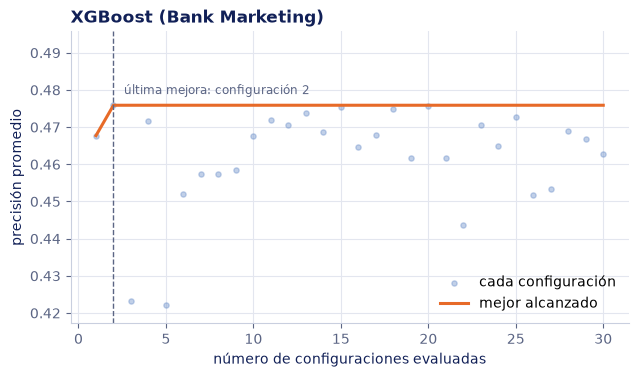

Mejor: 0.4759 | a la mitad (15 configuraciones) ya se tenía 0.4759 | mejora en la segunda mitad: +0.0000


In [32]:
pipe_xgb_b = Pipeline([("prep", prep_arboles_b()),
                       ("clf", XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEMILLA, verbosity=0))])
ESPACIO_XGB_B = {"clf__n_estimators": randint(100, 801),
                 "clf__learning_rate": loguniform(0.01, 0.2),
                 "clf__max_depth": randint(2, 9),
                 "clf__min_child_weight": loguniform(0.5, 30),
                 "clf__reg_lambda": loguniform(1e-2, 30),
                 "clf__reg_alpha": loguniform(1e-3, 10),
                 "clf__subsample": uniform(0.5, 0.5),
                 "clf__colsample_bytree": uniform(0.4, 0.6),
                 "clf__scale_pos_weight": [1.0, 3.0, 7.9]}
cvr_xgb_b, i_xgb_b = buscar(pipe_xgb_b, ESPACIO_XGB_B, X_b, y_b, CV_BANCO, SCORING_BUSQ_B, n_iter=30, criterio="ap")
params_xgb_b = cvr_xgb_b.loc[i_xgb_b, "params"]
graficar_meseta(cvr_xgb_b, "XGBoost (Bank Marketing)", criterio="ap", etiqueta="precisión promedio")

In [33]:
def mejor_rf_b():
    return clone(pipe_rf_b).set_params(**params_rf_b)


def mejor_lgbm_b():
    return clone(pipe_lgbm_b).set_params(**params_lgbm_b)


def mejor_xgb_b():
    return clone(pipe_xgb_b).set_params(**params_xgb_b)


# la mejor configuración de cada búsqueda, con el umbral de 0.5 (resultados de la propia búsqueda)
registrar_busqueda(RES_B, "Random Forest (optimizado)", "Bagging", cvr_rf_b, i_rf_b, mejor_rf_b)
registrar_busqueda(RES_B, "LightGBM (optimizado)", "Boosting", cvr_lgbm_b, i_lgbm_b, mejor_lgbm_b)
registrar_busqueda(RES_B, "XGBoost (optimizado)", "Boosting", cvr_xgb_b, i_xgb_b, mejor_xgb_b)

# las mismas configuraciones con el umbral ajustado dentro del modelo
registrar(RES_B, "Random Forest (optimizado) + umbral", "Bagging", lambda: con_umbral(mejor_rf_b()),
          X_b, y_b, CV_BANCO, SCORING_B, config=formatear(params_rf_b) + "; umbral ajustado")
registrar(RES_B, "LightGBM (optimizado) + umbral", "Boosting", lambda: con_umbral(mejor_lgbm_b()),
          X_b, y_b, CV_BANCO, SCORING_B, config=formatear(params_lgbm_b) + "; umbral ajustado")
registrar(RES_B, "XGBoost (optimizado) + umbral", "Boosting", lambda: con_umbral(mejor_xgb_b()),
          X_b, y_b, CV_BANCO, SCORING_B, config=formatear(params_xgb_b) + "; umbral ajustado")
registrar(RES_B, "AdaBoost (400 tocones) + umbral", "Boosting",
          lambda: con_umbral(Pipeline([("prep", prep_arboles_b()),
                                       ("clf", AdaBoostClassifier(DecisionTreeClassifier(max_depth=1),
                                                                  n_estimators=400, random_state=SEMILLA))])),
          X_b, y_b, CV_BANCO, SCORING_B, config="400 rondas, learning_rate=1; umbral ajustado")

Random Forest (optimizado) + umbral                  F1-macro 0.7181 ± 0.0057 | sens. 0.554 | 9.47 s por pliegue


LightGBM (optimizado) + umbral                       F1-macro 0.7187 ± 0.0060 | sens. 0.543 | 5.30 s por pliegue


XGBoost (optimizado) + umbral                        F1-macro 0.7161 ± 0.0063 | sens. 0.544 | 4.13 s por pliegue


AdaBoost (400 tocones) + umbral                      F1-macro 0.7070 ± 0.0059 | sens. 0.541 | 18.48 s por pliegue


## 2.5 Combinaciones: votación suave y stacking

Se combinan los mejores modelos de familias distintas: la regresión logística (preprocesamiento nuevo), Random Forest, LightGBM y XGBoost optimizados.

- **Votación suave + umbral:** promedio de las cuatro probabilidades y umbral ajustado por F1-macro.
- **Stacking:** las probabilidades de los cuatro, con 3 pliegues internos, alimentan una regresión logística cuyo umbral también se ajusta (con 5 pliegues sobre esas probabilidades internas, lo que no requiere reentrenar a los cuatro).

In [34]:
def miembros_b():
    return [("logistica", Pipeline([("prep", prep_lineal()), ("clf", logistica())])),
            ("rf", mejor_rf_b()), ("lgbm", mejor_lgbm_b()), ("xgb", mejor_xgb_b())]


def receta_voto_b():
    return con_umbral(VotingClassifier(miembros_b(), voting="soft"))


def receta_stacking_b():
    meta = TunedThresholdClassifierCV(LogisticRegression(max_iter=1000), scoring="f1_macro",
                                      cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA))
    return StackingClassifier(miembros_b(), final_estimator=meta,
                              cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA),
                              stack_method="predict_proba")


registrar(RES_B, "Votación suave (LR, RF, LGBM, XGB) + umbral", "Combinación", receta_voto_b,
          X_b, y_b, CV_BANCO, SCORING_B, config="promedio de probabilidades; umbral ajustado")
registrar(RES_B, "Stacking (LR, RF, LGBM, XGB → logística + umbral)", "Combinación", receta_stacking_b,
          X_b, y_b, CV_BANCO, SCORING_B, config="3 pliegues internos; meta-modelo logístico con umbral ajustado")

Votación suave (LR, RF, LGBM, XGB) + umbral          F1-macro 0.7178 ± 0.0051 | sens. 0.547 | 19.91 s por pliegue


Stacking (LR, RF, LGBM, XGB → logística + umbral)    F1-macro 0.7178 ± 0.0056 | sens. 0.550 | 20.09 s por pliegue


## 2.6 Tabla de modelos, matriz de confusión del mejor y comparación con la deserción

In [35]:
tabla_b = tabla_resultados(RES_B, "sens. yes")
tabla_b

,familia,F1-macro (media ± desv.),sens. yes,tiempo de entrenamiento (s/pliegue),configuración
modelo,,,,,
LightGBM (optimizado) + umbral,Boosting,0.7187 ± 0.0060,0.543,5.30,"class_weight=None, colsample_bytree=0.5192, learning_rate=0.01017, max_depth=6, min_child_samples=90, n_estimators=491, num_leaves=42, reg_alpha=1.448, reg_..."
Random Forest (optimizado) + umbral,Bagging,0.7181 ± 0.0057,0.554,9.47,"class_weight=None, criterion=gini, max_depth=12, max_features=0.3, max_samples=0.8, min_samples_leaf=23; umbral ajustado"
"Stacking (LR, RF, LGBM, XGB → logística + umbral)",Combinación,0.7178 ± 0.0056,0.550,20.09,3 pliegues internos; meta-modelo logístico con umbral ajustado
"Votación suave (LR, RF, LGBM, XGB) + umbral",Combinación,0.7178 ± 0.0051,0.547,19.91,promedio de probabilidades; umbral ajustado
XGBoost (optimizado) + umbral,Boosting,0.7161 ± 0.0063,0.544,4.13,"colsample_bytree=0.6002, learning_rate=0.01534, max_depth=4, min_child_weight=0.544, n_estimators=443, reg_alpha=2.137, reg_lambda=0.05474, scale_pos_weight..."
AdaBoost (400 tocones) + umbral,Boosting,0.7070 ± 0.0059,0.541,18.48,"400 rondas, learning_rate=1; umbral ajustado"
Regresión logística (preproc. nuevo) + umbral,Base,0.7070 ± 0.0062,0.511,2.16,"C=1, umbral ajustado por F1-macro (CV interna)"
XGBoost (optimizado) (receta de la deserción),Boosting,0.6974 ± 0.0047,0.604,3.56,"sin reoptimizar: class_weight=balanced, colsample_bytree=0.9695, gamma=1, learning_rate=0.01167, max_depth=8, min_child_weight=0.529, n_estimators=541, reg_..."
SVM (receta de la deserción),Base,0.6951 ± 0.0069,0.406,24.63,"sin reoptimizar: C=172.8, gamma=0.0007778, class_weight={0: 1.0, 1: 2.0, 2: 1.0}, min_freq=10"


Mejor modelo de Bank Marketing: LightGBM (optimizado) + umbral | class_weight=None, colsample_bytree=0.5192, learning_rate=0.01017, max_depth=6, min_child_samples=90, n_estimators=491, num_leaves=42, reg_alpha=1.448, reg_lambda=0.5164, subsample=0.9632; umbral ajustado


cross_validate(scoring='f1_macro'): 0.7187 ± 0.0060 | tabla: 0.7187 ± 0.0060


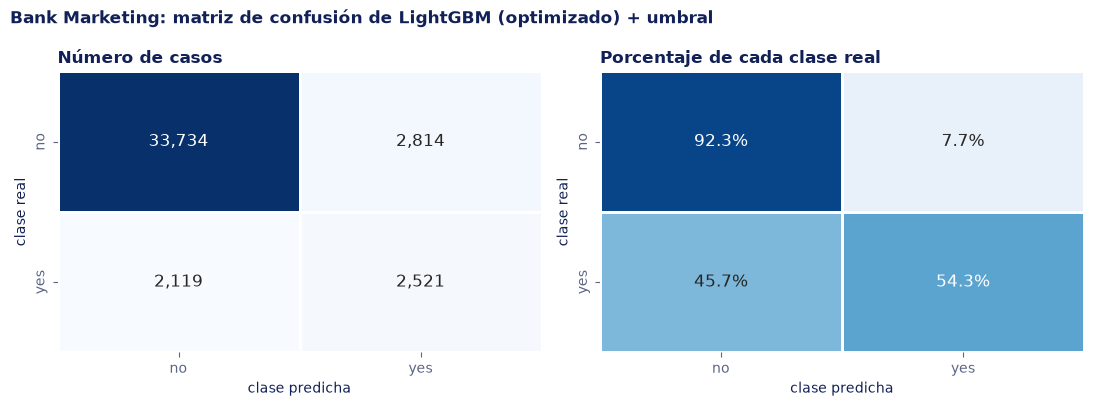

Llamaría a 5,335 clientes (13.0%); acepta el 47.3% de ellos. Encuentra 2,521 de los 4,640 que aceptan (sensibilidad 0.543).


In [36]:
mejor_b = tabla_b.index[0]
print("Mejor modelo de Bank Marketing:", mejor_b, "|", RES_B[mejor_b]["config"])

# Comprobación literal del enunciado: el F1-macro sale de cross_validate(..., scoring="f1_macro")
r_lit = cross_validate(RES_B[mejor_b]["receta"](), X_b, y_b,
                       cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2026), scoring="f1_macro")
print(f"cross_validate(scoring='f1_macro'): {r_lit['test_score'].mean():.4f} ± {r_lit['test_score'].std():.4f} | "
      f"tabla: {RES_B[mejor_b]['f1'].mean():.4f} ± {RES_B[mejor_b]['f1'].std():.4f}")

y_oof_b = cross_val_predict(RES_B[mejor_b]["receta"](), X_b, y_b, cv=CV_BANCO, n_jobs=-1)
cm_b = graficar_confusion(y_b, y_oof_b, CLASES_B, f"Bank Marketing: matriz de confusión de {mejor_b}")
tn, fp, fn, tp = cm_b.ravel()
print(f"Llamaría a {tp + fp:,} clientes ({(tp + fp) / len(y_b):.1%}); acepta el {tp / (tp + fp):.1%} de ellos. "
      f"Encuentra {tp:,} de los {tp + fn:,} que aceptan (sensibilidad {tp / (tp + fn):.3f}).")

In [37]:
def resumen_familias(tabla):
    df = pd.DataFrame([{"modelo": n, "familia": d["familia"], "F1": d["f1"].mean()} for n, d in tabla.items()
                       if d["familia"] != "Línea base"])
    return df.loc[df.groupby("familia")["F1"].idxmax()].set_index("familia")


fam_des, fam_b = resumen_familias(RES), resumen_familias(RES_B)
comp = pd.DataFrame({"deserción: mejor modelo": fam_des["modelo"], "deserción: F1-macro": fam_des["F1"],
                     "bank: mejor modelo": fam_b["modelo"], "bank: F1-macro": fam_b["F1"]})
comp["deserción: Δ contra el mejor base"] = comp["deserción: F1-macro"] - comp.loc["Base", "deserción: F1-macro"]
comp["bank: Δ contra el mejor base"] = comp["bank: F1-macro"] - comp.loc["Base", "bank: F1-macro"]
display(comp.round(4))

efectos_umbral = {
    "Regresión logística": ("Regresión logística (preproc. nuevo)", "Regresión logística (preproc. nuevo) + umbral"),
    "Random Forest": ("Random Forest (optimizado)", "Random Forest (optimizado) + umbral"),
    "LightGBM": ("LightGBM (optimizado)", "LightGBM (optimizado) + umbral"),
    "XGBoost": ("XGBoost (optimizado)", "XGBoost (optimizado) + umbral"),
}
print("Efecto del umbral ajustado en Bank Marketing (ΔF1-macro, misma configuración):")
for n, (a, b) in efectos_umbral.items():
    print(f"  {n:<20} {RES_B[a]['f1'].mean():.4f} → {RES_B[b]['f1'].mean():.4f} "
          f"({RES_B[b]['f1'].mean() - RES_B[a]['f1'].mean():+.4f}); sensibilidad de yes "
          f"{RES_B[a]['sens'].mean():.3f} → {RES_B[b]['sens'].mean():.3f}")
print(f"\nReceta de la deserción ({mejor_des}) en Bank Marketing: {RES_B[nombre_tr]['f1'].mean():.4f}; "
      f"mejor modelo reoptimizado: {RES_B[mejor_b]['f1'].mean():.4f}")

ref_b = comp.loc["Base", "bank: mejor modelo"]
f1_ref_b = RES_B[ref_b]["f1"]
print(f"\nBank Marketing: diferencias pareadas contra el mejor modelo no ensamble ({ref_b}):")
pd.DataFrame([{
    "modelo": n, "familia": d["familia"],
    "ΔF1 (media)": (d["f1"] - f1_ref_b).mean(),
    "desv. de la diferencia": (d["f1"] - f1_ref_b).std(),
    "pliegues en que gana": int(((d["f1"] - f1_ref_b) > 0).sum()),
} for n, d in RES_B.items() if d["familia"] in ("Bagging", "Boosting", "Combinación")]
).sort_values("ΔF1 (media)", ascending=False).set_index("modelo").round(4)

,deserción: mejor modelo,deserción: F1-macro,bank: mejor modelo,bank: F1-macro,deserción: Δ contra el mejor base,bank: Δ contra el mejor base
familia,,,,,,
Bagging,Random Forest (optimizado),0.6825,Random Forest (optimizado) + umbral,0.7181,-0.0061,0.0110
Base,SVM,0.6886,Regresión logística (preproc. nuevo) + umbral,0.7070,0.0000,0.0000
Boosting,XGBoost (optimizado),0.6949,LightGBM (optimizado) + umbral,0.7187,0.0063,0.0117
Combinación,Stacking (5 base → logística con pesos balanced),0.6919,"Stacking (LR, RF, LGBM, XGB → logística + umbral)",0.7178,0.0033,0.0108


Efecto del umbral ajustado en Bank Marketing (ΔF1-macro, misma configuración):
  Regresión logística  0.6403 → 0.7070 (+0.0667); sensibilidad de yes 0.224 → 0.511
  Random Forest        0.6475 → 0.7181 (+0.0706); sensibilidad de yes 0.236 → 0.554
  LightGBM             0.6582 → 0.7187 (+0.0605); sensibilidad de yes 0.257 → 0.543
  XGBoost              0.6538 → 0.7161 (+0.0622); sensibilidad de yes 0.246 → 0.544

Receta de la deserción (XGBoost (optimizado)) en Bank Marketing: 0.6974; mejor modelo reoptimizado: 0.7187

Bank Marketing: diferencias pareadas contra el mejor modelo no ensamble (Regresión logística (preproc. nuevo) + umbral):


,familia,ΔF1 (media),desv. de la diferencia,pliegues en que gana
modelo,,,,
LightGBM (optimizado) + umbral,Boosting,0.0117,0.0031,5
Random Forest (optimizado) + umbral,Bagging,0.0110,0.0019,5
"Stacking (LR, RF, LGBM, XGB → logística + umbral)",Combinación,0.0108,0.0027,5
"Votación suave (LR, RF, LGBM, XGB) + umbral",Combinación,0.0108,0.0030,5
XGBoost (optimizado) + umbral,Boosting,0.0090,0.0030,5
AdaBoost (400 tocones) + umbral,Boosting,0.0000,0.0016,2
XGBoost (optimizado) (receta de la deserción),Boosting,-0.0097,0.0032,0
LightGBM (optimizado),Boosting,-0.0488,0.0055,0
XGBoost (optimizado),Boosting,-0.0532,0.0041,0


**El mejor modelo de Bank Marketing** es **LightGBM optimizado con umbral ajustado: F1-macro 0.7187 ± 0.0060**, sensibilidad de *yes* 0.543. Sin pesos por clase, usa 491 árboles poco profundos (profundidad ≤ 6, 42 hojas) con tasa 0.010 y regularización L1 y L2. En la matriz de confusión: llamaría al 13.0 % de los clientes (5,335), de los cuales acepta el 47.3 %, y encuentra a 2,521 de los 4,640 que aceptan. Llamando al azar a la misma cantidad de clientes, solo aceptaría el 11.3 %. La comprobación con `cross_validate(..., scoring="f1_macro")` da exactamente el mismo valor de la tabla.

**¿Funcionó lo mismo que en la deserción, y por qué?** En parte sí y en parte no:

1. **Lo que funcionó igual: los ensambles ganan poco.** Los cinco mejores modelos (LightGBM, Random Forest, *stacking*, votación suave y XGBoost, todos con umbral) están entre 0.716 y 0.719, a menos de una desviación entre sí, y le sacan apenas **+0.009 a +0.012** a la regresión logística con umbral (0.7070). La diferencia con la deserción es que esa ganancia pequeña **sí es real**: la desviación de la diferencia pareada es de 0.002 a 0.003 y los cinco ensambles ganan en **los 5 pliegues**. En la deserción, la mejor ganancia (+0.006) tenía una desviación de 0.014 y ganaba en 3 de 5.
2. **Lo que cambió: el umbral pesa mucho más que el ensamble.** Con la misma configuración, ajustar el umbral sube el F1-macro **entre 0.06 y 0.07** en los cuatro modelos (por ejemplo, Random Forest de 0.648 a 0.718), seis veces más que cambiar la regresión logística por el mejor ensamble. Sin umbral, los ensambles optimizados (0.648 a 0.658) quedan **por debajo** de la regresión logística con umbral. En la deserción, con tres clases y un desbalance moderado, este papel lo cumplían los pesos por clase.
3. **La receta trasladada no es la solución.** XGBoost con su configuración de la deserción queda en 0.6974, por debajo incluso de la regresión logística con umbral, porque su frontera quedó elegida para otro problema.

**Por qué.** En Bank Marketing, la información está en atributos con pocos valores (los indicadores macroeconómicos, que cambian por mes de campaña, `pdays`, `poutcome`, el mes) y en sus **cortes e interacciones**, justo lo que modelan los árboles, y 41 mil clientes bastan para que los aprendan sin sobreajustar; eso explica la ganancia consistente de las familias de árboles sobre el modelo lineal. Que la ganancia sea pequeña se debe a que la decisión del cliente depende sobre todo de cosas que no están en los datos (la precisión promedio de los mejores ensambles optimizados no pasa de 0.48), y todos los modelos se equivocan en los mismos clientes.

## 2.7 Modelo final 

El mejor modelo de Bank Marketing se entrena con los 41,188 clientes y se guarda con `joblib`. Recibe un `DataFrame` con las 19 columnas del archivo (sin `duration` ni `y`) y devuelve 1 (*yes*) o 0 (*no*); el preprocesamiento y el umbral están dentro del objeto.

In [38]:
RUTA_MODELO = "erick-santiago-modelo.joblib"
modelo_final = RES_B[mejor_b]["receta"]()
t0 = time.perf_counter()
modelo_final.fit(X_b, y_b)
print(f"Entrenado con {len(y_b):,} clientes en {time.perf_counter() - t0:.1f} s")
joblib.dump(modelo_final, RUTA_MODELO)

cargado = joblib.load(RUTA_MODELO)
assert (cargado.predict(X_b) == modelo_final.predict(X_b)).all()
print(f"Guardado en {RUTA_MODELO} ({os.path.getsize(RUTA_MODELO) / 1e6:.1f} MB); al cargarlo da las mismas predicciones.")
if hasattr(cargado, "best_threshold_"):
    print(f"Umbral elegido con todo el conjunto: {cargado.best_threshold_:.3f}")
if b"__main__" in pickle.dumps(modelo_final):
    print("Aviso: el modelo usa una clase definida en este notebook (PesosPorClase); "
          "para cargarlo en otra sesión hay que definirla antes de joblib.load.")
print("Modelo:", type(cargado).__name__, "| entradas:", list(X_b.columns))

Entrenado con 41,188 clientes en 6.0 s


Guardado en erick-santiago-modelo.joblib (1.8 MB); al cargarlo da las mismas predicciones.
Umbral elegido con todo el conjunto: 0.271
Modelo: TunedThresholdClassifierCV | entradas: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


---

# Conclusiones

Las tablas de diferencias pareadas (sección 1.6) y la comparación por familias (sección 2.6) resumen lo que aportó cada familia de ensambles en los dos problemas.

**Bagging (árbol sin límite → bagging → Random Forest y Extra-Trees).** Reduce la varianza: en la deserción subió el árbol sin límite de 0.596 a 0.661 con el mismo F1 de entrenamiento (1.0), y la curva se aplanó desde unos 50 árboles, porque lo que queda es la correlación entre árboles. Random Forest y Extra-Trees bajan esa correlación y, con pesos por clase, llegan a 0.683 y 0.678, todavía por debajo del SVM (0.689): promediar no corrige el sesgo de los cortes paralelos a los ejes en un problema casi lineal. En Bank Marketing, donde la señal está en cortes de atributos con pocos valores, Random Forest con umbral (0.718) le gana a la regresión logística con umbral en los 5 pliegues.

**Boosting (tocón → AdaBoost → XGBoost y LightGBM).** Reduce el sesgo: AdaBoost llevó al tocón, que solo predice dos de las tres clases (0.492), a 0.642, con el F1 de entrenamiento subiendo junto con el de validación. El *gradient boosting* optimizado agrega regularización y submuestreo y fue la mejor familia en los dos problemas: XGBoost en la deserción (0.695) y LightGBM en Bank Marketing (0.719). Pero en la deserción su ventaja sobre el SVM (+0.006) es menor que la desviación entre pliegues.

**Combinar los cinco base (votación dura, suave y stacking).** Su ganancia está limitada por la **correlación de los errores**: los cinco fallan a la vez en 11.8 % de los estudiantes, contra 0.2 % si fueran independientes, y el SVM y la regresión logística tienen errores casi iguales (φ = 0.84). Por eso la votación dura apenas iguala al SVM (+0.002). La votación suave y el *stacking* con meta-modelo logístico simple quedan por debajo (0.676 y 0.675) porque, al combinar probabilidades sin pesos, pierden el refuerzo de *Enrolled*; con pesos `balanced` en el meta-modelo, el *stacking* lo recupera (0.692). En Bank Marketing, votación y *stacking* de cuatro modelos distintos (0.718) no superan al mejor de sus miembros (LightGBM, 0.719): combinar modelos que se equivocan en los mismos clientes no agrega información.

**Diferencias entre los dos conjuntos y qué las explica.**

| Característica | Deserción | Bank Marketing | Efecto en los ensambles |
|---|---|---|---|
| Tamaño | 3,539 | 41,188 | Con más datos, las diferencias pequeñas se vuelven estables: la desviación entre pliegues baja de ~0.01 a ~0.006, y una ganancia de 0.01 se distingue del ruido |
| Clases | 3; la minoritaria es el 18 % | 2; la positiva es el 11 % | En Bank, el umbral sube el F1-macro de 0.06 a 0.07 en todos los modelos; en la deserción, los pesos por clase cumplen ese papel |
| Forma de la señal | Casi lineal, concentrada en el desempeño académico | Cortes e interacciones en atributos con pocos valores (macroeconomía, `pdays`, `poutcome`, mes) | El SVM y la regresión logística ya alcanzan el techo en la deserción; los árboles le sacan una ventaja consistente al modelo lineal en Bank |
| Error irreducible | Grande (*Enrolled* contra *Dropout* con desempeño intermedio) | Grande (la decisión del cliente depende de cosas que no están en los datos) | Ningún ensamble crea información; los errores se vuelven correlacionados y el techo es parecido para todos |

**Respuesta a la pregunta de la práctica.** Cuando los cinco clasificadores base ya están bien ajustados, los ensambles **casi no ganan** en la deserción: el mejor, XGBoost, supera al SVM por 0.006 de F1-macro (0.695 contra 0.689), con una desviación de la diferencia de 0.014 y ganando en 3 de 5 pliegues, lo que no se distingue del ruido, y entrenarlo cuesta más de diez veces más (3.6 s contra 0.3 s por pliegue). Los ensambles ganan mucho solo cuando el modelo base es débil: +0.065 para el árbol sin límite con bagging y +0.150 para el tocón con AdaBoost. En Bank Marketing la historia es parecida, pero con más datos y una señal hecha de cortes, los ensambles de árboles le ganan a la regresión logística por unos 0.01 en todos los pliegues. Aun así, lo que más mejoró el F1-macro en ese problema no fue el ensamble sino el **umbral** ajustado dentro del modelo (+0.06 a +0.07).

---

### Declaración de uso de IA generativa

Este notebook utilizó Claude (Anthropic) como asistente para estructurar el notebook (Markdown), redactar y revisar los textos, así como la depuración de código. 

### Referencias

- Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data, 7*(11), 146. https://doi.org/10.3390/data7110146 · Conjunto de datos: https://doi.org/10.24432/C5MC89 (CC BY 4.0).
- Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems, 62*, 22-31. https://doi.org/10.1016/j.dss.2014.03.001 · Conjunto de datos: https://doi.org/10.24432/C5K306 (CC BY 4.0).
- Breiman, L. (1996). Bagging predictors. *Machine Learning, 24*(2), 123-140.
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32.
- Geurts, P., Ernst, D., & Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning, 63*(1), 3-42.
- Freund, Y., & Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences, 55*(1), 119-139.
- Zhu, J., Zou, H., Rosset, S., & Hastie, T. (2009). Multi-class AdaBoost. *Statistics and Its Interface, 2*(3), 349-360.
- Friedman, J., Hastie, T., & Tibshirani, R. (2000). Additive logistic regression: a statistical view of boosting. *The Annals of Statistics, 28*(2), 337-407.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *KDD '16*, 785-794.
- Ke, G., *et al.* (2017). LightGBM: A highly efficient gradient boosting decision tree. *NeurIPS 30*.
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241-259.
- Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. *Advances in Large Margin Classifiers*, 61-74.
- scikit-learn: [Ensembles](https://scikit-learn.org/stable/modules/ensemble.html) · [CalibratedClassifierCV](https://scikit-learn.org/stable/modules/calibration.html) · [TunedThresholdClassifierCV](https://scikit-learn.org/stable/modules/classification_threshold.html) · [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)